# Analisis performa persona agama — ETHICS

Penyelarasan dengan gender, 6 Oktober 2026. Akurasi hanya disajikan per subset Commonsense/Justice; Deontology/Virtue memakai distribusi jawaban. Status dan coverage tetap tersedia untuk semua subset. Tidak ada parsing/scoring/uji ulang.

## Konsistensi dan batas interpretasi

Ateis/Kristen/Islam/Yahudi, N/E/I1/I2/I3, warna E/I, nama model dan arah kiri−kanan konsisten lintas benchmark. Warna status berbeda dari warna identitas karena maknanya berbeda. Rerata I1–I3 hanya deskriptif. Heatmap memakai skala kontinu; data tidak dipudarkan berdasarkan p-value. NA bukan nol.

Bintang selalu p Holm <0,05, termasuk pada heatmap p mentah. Ukuran keluarga tetap sesuai sumber: vs N 16, kontras lengkap per subset 7/24. Signifikansi tidak otomatis berarti efek besar atau efek identitas murni.

## 1. SPEC

154.428 respons, enam model, 17 skenario, empat subset eksperimen. Tujuan perubahan adalah presentasi dan provenance; sumber hasil tetap beku. Bab VI tidak diubah.

## 2. DESIGN PLAN

Baca tabel lokal, validasi penyebut dan arah; render PNG baru dari notebook; arsipkan semua aset terdahulu; pasang hasil setelah lolos pemeriksaan. Tiga jenis heatmap kontras lengkap tersedia per subset valid, bukan gabungan kecocokan label. Empat gambar gabungan lama tetap dapat dibuka melalui arsip, bukan dipromosikan sebagai hasil akurasi ETHICS.

## 3. IMPLEMENTATION — konfigurasi dan sumber

In [1]:
BENCHMARK="ETHICS"
FOLDER="ethics accuracy analysis"
NOTEBOOK_NAME="ETHICS_Religion_Accuracy_Analysis_Lengkap.ipynb"
from pathlib import Path
from datetime import datetime
import ast, hashlib, json, re, shutil, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.text import Text
from matplotlib.collections import PathCollection
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'AGENTS.md').is_file())
sys.path.insert(0,str(ROOT))
sys.path.insert(0,str(ROOT/'src/pipelines/analysis'))
ACTIVE = ROOT/'notebooks/religion'/FOLDER
TABLE_DIR = (ROOT/'result/benchmarks/gsm8k/reports/persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold/tables') if BENCHMARK=='GSM8K' else ACTIVE/'tables'
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN = ROOT/'result/analyses/accuracy/runs'/('religion_'+BENCHMARK.lower()+'_presentation_'+RUN_ID)
FIGURE_DIR = RUN/'figures'
FIGURE_DIR.mkdir(parents=True,exist_ok=False)
def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
TABLE_HASHES = {str(p.resolve()):file_hash(p) for p in TABLE_DIR.glob('*.csv')}
LEGACY_STEMS = {'00_ethics_religion_combined_absolute_accuracy','00_ethics_religion_combined_inference_effect_holm','00_ethics_religion_combined_exact_mcnemar_four_panels','00_ethics_religion_combined_holm_pvalue_four_panels'}
MODEL_SOURCE = ['Qwen3 Next 80B-A3B','Llama 3.1 8B','Ministral 8B','DeepSeek R1-Distill 32B','GPT-OSS 20B','Llama 3.3 70B']
IDENTITIES = ['atheist','christian','islam','jewish']
IL = dict(zip(IDENTITIES,['Ateis','Kristen','Islam','Yahudi']))
PERSONAS = [i+'_'+c for i in IDENTITIES for c in ['explicit','implicit_1','implicit_2','implicit_3']]+['neutral']
PERSONA_LABELS = [IL[i]+' '+c for i in IDENTITIES for c in ['E','I1','I2','I3']]+['Neutral']
CATEGORIES = [IL[i]+' '+c for i in IDENTITIES for c in ['Explicit','Implicit Avg']]+['Neutral']
COLORS = ['#0047AB','#0086A8','#B80F2E','#E45700','#007A4D','#66A61E','#5B21B6','#A0006D','#30343B']
BACKGROUND = '#FCFBF8'
FONT_SIZES = dict(title=30,panel=26,axis=22,colorbar=25,cell=26)
RENDER_AUDIT = []
def display_label(value):
    s=str(value).replace('80B-A3B','80B')
    for old,new in [('DeepSeek R1-Distill','DeepSeek R1'),('Qwen3 Next 80B-A3B','Qwen3 Next 80B'),('Atheist','Ateis'),('Christian','Kristen'),('Jewish','Yahudi'),('Religion Persona & Baseline','Persona agama dan skenario netral'),('Religion','Agama'),('Global Neutral Avg','Rerata N enam model'),('Neutral Avg','Rerata N'),('Implicit Avg','Rerata I1–I3'),('Explicit','E'),('Implicit','I'),('Neutral','N'),('Accuracy','Akurasi'),('Difference on accuracy scale','Delta akurasi (skala 0–1)')]:
        s=s.replace(old,new)
    return s
def plot_values(fig):
    values=[]
    for ax in fig.axes:
        values += [np.array(line.get_xydata(),copy=True) for line in ax.lines]
        values += [np.array([p.get_x(),p.get_y(),p.get_width(),p.get_height()]) for p in ax.patches if hasattr(p,'get_height')]
        values += [np.array(c.get_array(),copy=True) for c in ax.collections if c.get_array() is not None]
    return values
def format_figure(fig):
    before=plot_values(fig)
    for ax in fig.axes:
        xlim,ylim=ax.get_xlim(),ax.get_ylim()
        for name in ['x','y']:
            texts=getattr(ax,'get_'+name+'ticklabels')()
            if any(display_label(t.get_text())!=t.get_text() for t in texts):
                getattr(ax,'set_'+name+'ticks')(getattr(ax,'get_'+name+'ticks')(),[display_label(t.get_text()) for t in texts])
        ax.set_xlim(xlim);ax.set_ylim(ylim)
        ax.title.set_fontweight('bold')
        for p in ax.patches:
            if hasattr(p,'get_height'): p.set_alpha(1)
        for c in ax.collections:
            if isinstance(c,PathCollection): c.set_alpha(1)
    for ax in fig.axes:
        for collection in ax.collections:
            a=collection.get_array()
            if a is not None and np.ndim(a)==2:
                for y,x in np.argwhere(np.ma.getmaskarray(a)):
                    ax.text(x+.5,y+.5,'NA',ha='center',va='center',fontsize=12,color='#17212B')
    for t in fig.findobj(Text): t.set_text(display_label(t.get_text()))
    if fig._suptitle: fig._suptitle.set_fontweight('bold')
    after=plot_values(fig)
    assert len(before)==len(after)
    assert all(np.array_equal(a,b,equal_nan=True) for a,b in zip(before,after))
    return len(before)
def save_plot(fig,stem,detail=''):
    arrays=format_figure(fig)
    path=FIGURE_DIR/(stem+'.png')
    assert not path.exists(),path
    fig.savefig(path,dpi=220,facecolor=BACKGROUND,bbox_inches='tight',pad_inches=.25)
    plt.close(fig)
    RENDER_AUDIT.append(dict(file=path.name,numeric_arrays_unchanged=arrays,detail=detail))
    print('PNG:',path.name,flush=True)
    return path
def show_figure(name,width=1300):
    if not name.endswith('.png'): name+='.png'
    display(Image(filename=str(ACTIVE/'figures'/name),width=width))
def publish():
    assert all(file_hash(p)==h for p,h in TABLE_HASHES.items())
    # Preserve PNG types not regenerated; invalid pooled accuracy remains in the archive.
    for p in (ACTIVE/'figures').glob('*.png'):
        if p.stem not in LEGACY_STEMS and not (FIGURE_DIR/p.name).exists():
            shutil.copy2(p,FIGURE_DIR/p.name)
    assert not list(FIGURE_DIR.glob('*.svg'))
    for p in FIGURE_DIR.glob('*.png'):
        with PILImage.open(p) as im: im.verify()
    archive=ACTIVE/'_arsip'/('accuracy_before_'+RUN_ID)
    archive.mkdir(parents=True,exist_ok=False)
    for target in [ACTIVE/'figures',archive]:
        assert target.resolve().is_relative_to((ROOT/'notebooks/religion').resolve())
    old={str(p.relative_to(ACTIVE/'figures')):file_hash(p) for p in (ACTIVE/'figures').rglob('*') if p.is_file()}
    shutil.move(str(ACTIVE/'figures'),str(archive/'figures'))
    assert old=={str(p.relative_to(archive/'figures')):file_hash(p) for p in (archive/'figures').rglob('*') if p.is_file()}
    for name in ['README.md','LATEST_RUN.json','output_index.csv','active_figures.csv','presentation_manifest.json','bundle_manifest.json']:
        if (ACTIVE/name).exists(): shutil.copy2(ACTIVE/name,archive/name)
    shutil.copy2(ACTIVE/NOTEBOOK_NAME,archive/NOTEBOOK_NAME)
    shutil.copytree(FIGURE_DIR,ACTIVE/'figures')
    index=pd.DataFrame([dict(kind='figure',file=p.name,relative_path='figures/'+p.name,path=str(ACTIVE/'figures'/p.name),sha256=file_hash(p),status='regenerated' if p.name in {r['file'] for r in RENDER_AUDIT} else 'preserved_supporting_png') for p in sorted(FIGURE_DIR.glob('*.png'))])
    index.to_csv(RUN/'figure_index.csv',index=False)
    index.to_csv(ACTIVE/'output_index.csv',index=False)
    index.rename(columns={'relative_path':'figure'}).to_csv(ACTIVE/'active_figures.csv',index=False)
    manifest=dict(benchmark=BENCHMARK,run=str(RUN),archive=str(archive),source_table_hashes=TABLE_HASHES,rendered=RENDER_AUDIT,png=len(index),svg=0,new_tests=False,rescoring=False,api_calls=0,latex_changed=False,legacy_pooled_accuracy_excluded=sorted(LEGACY_STEMS) if BENCHMARK=='ETHICS' else [])
    (RUN/'presentation_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    (ACTIVE/'presentation_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    (ACTIVE/'LATEST_RUN.json').write_text(json.dumps({'run':str(RUN),'archive':str(archive)},indent=2),encoding='utf-8')
    (archive/'preserved_hashes.json').write_text(json.dumps(old,indent=2),encoding='utf-8')
    assert all(file_hash(ACTIVE/'figures'/r['file'])==r['sha256'] for r in index.to_dict('records'))
    print('PUBLISH_OK',BENCHMARK,len(index),'PNG; sumber statistik tidak berubah.',flush=True)
    return manifest
sns.set_theme(style='whitegrid',font='DejaVu Sans')
plt.rcParams.update({'figure.facecolor':BACKGROUND,'axes.facecolor':BACKGROUND,'axes.titleweight':'bold','font.size':14,'axes.titlesize':23,'axes.labelsize':18,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':13})


## 4. CHECKLIST — validasi

In [2]:
summary=pd.read_csv(TABLE_DIR/'ethics_condition_summary_source_derived.csv')
paired_all=pd.read_csv(TABLE_DIR/'ethics_paired_effects_all.csv')
combined=pd.read_csv(TABLE_DIR/'ethics_religion_combined_four_subsets.csv')
status=pd.read_csv(TABLE_DIR/'ethics_status_by_model_persona_category.csv')
assert len(summary)==408 and int(summary.total.sum())==154428
assert not summary.duplicated(['model','persona','subset']).any()
assert summary.total.eq(summary.committed+summary.abstain+summary.missing).all()
assert summary.n_answer_wrong.add(summary.n_answer_acceptable).eq(summary.committed).all()
assert np.allclose(summary.accuracy_committed,summary.n_correct/summary.committed,equal_nan=True)
assert len(paired_all)==1248 and paired_all.groupby(['subset','model']).size().eq(52).all()
assert set(paired_all.holm_family_size)=={7,24}
assert np.allclose(paired_all.delta_accuracy_pp,paired_all.accuracy_a_pct-paired_all.accuracy_b_pct)
h=2*np.arcsin(np.sqrt(paired_all.accuracy_a_pct/100))-2*np.arcsin(np.sqrt(paired_all.accuracy_b_pct/100))
assert np.allclose(h,paired_all.cohens_h)
assert np.allclose(summary.commit_rate,summary.committed/summary.total)
assert len(combined)==54 and combined.subset_count.eq(4).all()
print('VALIDATION_OK: 154428 respons; 408 ringkasan; 1248 kontras; tidak ada p-value dihitung ulang.')


VALIDATION_OK: 154428 respons; 408 ringkasan; 1248 kontras; tidak ada p-value dihitung ulang.


## 5. Render akurasi, coverage, distribusi jawaban dan status

### Definisi visual

Commonsense/Justice: akurasi committed dan commit rate pada gambar yang sama. Deontology/Virtue: proporsi wrong di antara committed, bukan akurasi. Status menghitung seluruh respons. Grafik gabungan hanya stance/status deskriptif dengan bobot respons, bukan akurasi moral.

In [3]:
def category_plot(frame,metric,ax,ylabel):
    values=frame.pivot(index='model_label',columns='category',values=metric).reindex(index=MODEL_SOURCE,columns=CATEGORIES)
    values.plot(kind='bar',width=.86,color=COLORS,ax=ax)
    ax.set_ylabel(ylabel);ax.set_xlabel('Model');ax.tick_params(axis='x',rotation=0,labelsize=12)
    ax.set_ylim(0,1.08);ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),fontsize=11)
    return values
def render_stance_status_and_subsets():
    from dataclasses import replace
    from src.benchmarks.ethics import build_ethics_domain_accuracy_parity_v1 as parity
    config=replace(parity.CONFIGS['religion'],identities=tuple((i,IL[i],IL[i]) for i in IDENTITIES))
    old=parity.save_figure
    def parity_save(fig,directory,stem,overwrite):
        titles={fig._suptitle,*[ax.title for ax in fig.axes]}
        for t in fig.findobj(Text):
            if t not in titles: t.set_fontsize(t.get_fontsize()+4)
        return {'png':str(save_plot(fig,stem,'Status/coverage/alasan dari tabel beku'))}
    parity.save_figure=parity_save
    try:
        all_summary=pd.read_csv(TABLE_DIR/'ethics_religion_parity_all_subset_summary.csv')
        reasons=pd.read_csv(TABLE_DIR/'ethics_religion_parity_abstain_reasons.csv')
        parity.plot_status_heatmaps(all_summary,config,FIGURE_DIR,False)
        parity.plot_commit_rate_by_subset(summary,config,FIGURE_DIR,False)
        for metric,num,title in [('pct_of_abstain','04','Alasan di antara abstain'),('pct_of_nonmissing','05','Prevalensi alasan abstain')]:
            parity.plot_reason_heatmaps(reasons,config,FIGURE_DIR,False,metric=metric,stem_number=num,title=title,metric_label='Denominator: '+('abstain' if num=='04' else 'non-missing'))
        parity.plot_cramers_v(pd.read_csv(TABLE_DIR/'ethics_religion_parity_cramers_v.csv'),config,FIGURE_DIR,False)
    finally:
        parity.save_figure=old
    # All-subset stance and status are descriptive, not accuracy.
    for frame,stem,columns,labels in [
       (combined,'00_ethics_religion_combined_four_subsets_distribution',['pct_answer_wrong','pct_answer_acceptable'],['Wrong','Acceptable']),
       (status,'01_ethics_religion_status_composition_by_model',['commit_rate','abstain_rate','missing_rate'],['Committed','Abstain','Missing'])]:
        fig,axes=plt.subplots(2,3,figsize=(24,13),layout='constrained')
        for ax,model in zip(axes.flat,MODEL_SOURCE):
            data=frame[frame.model_label.eq(model)].set_index('category').reindex(CATEGORIES)
            bottom=np.zeros(9)
            for col,label,color in zip(columns,labels,['#2463EB','#D59000','#89939F']):
                ax.bar(np.arange(9),data[col],bottom=bottom,label=label,color=color);bottom+=data[col].to_numpy()
            ax.set_xticks(np.arange(9),[display_label(c).replace('Rerata I1–I3','I rata-rata') for c in CATEGORIES],rotation=45,ha='right')
            ax.set_ylim(0,1);ax.set_title(model,fontweight='bold');ax.legend(fontsize=11)
        fig.suptitle('ETHICS · Persona agama: '+('distribusi jawaban committed' if len(columns)==2 else 'status respons')+' — gabungan deskriptif',fontsize=23,fontweight='bold')
        fig.supxlabel('Berbobot jumlah respons tersedia; bukan akurasi gabungan. I rata-rata menggabungkan I1–I3.',fontsize=13)
        save_plot(fig,stem,'Gabungan deskriptif; bukan skor moral')
    matrix=combined.pivot(index='model_label',columns='category',values='pct_answer_wrong').reindex(MODEL_SOURCE)
    for implicit,stem in [(False,'00_ethics_religion_combined_delta_vs_neutral'),(True,'00_ethics_religion_combined_delta_implicit_explicit')]:
        if implicit:
            delta=pd.DataFrame({IL[i]+': rerata I1–I3 − E':matrix[IL[i]+' Implicit Avg']-matrix[IL[i]+' Explicit'] for i in IDENTITIES})
            colors=COLORS[::2][:-1]
        else:
            delta=pd.DataFrame({c+' − N':matrix[c]-matrix['Neutral'] for c in CATEGORIES[:-1]});colors=COLORS[:-1]
        fig,ax=plt.subplots(figsize=(24,9));(delta*100).plot.bar(ax=ax,color=colors,width=.85)
        ax.axhline(0,color='black');ax.set_ylabel('Delta proporsi wrong (poin persentase)');ax.set_xlabel('Model');ax.tick_params(axis='x',rotation=0)
        ax.set_title('ETHICS · Persona agama: delta distribusi jawaban — '+('I − E' if implicit else 'persona − N'),fontsize=23,fontweight='bold')
        ax.legend(bbox_to_anchor=(1.01,1),loc='upper left')
        fig.text(.5,-.02,'Deskriptif, berbobot committed; bukan delta akurasi dan bukan uji pasangan.',ha='center',fontsize=13)
        save_plot(fig,stem,'Nilai stance gabungan dari tabel; tanpa inferensi baru')
    counts=['total','committed','abstain','missing','n_correct','n_answer_wrong','n_answer_acceptable']
    for subset in ['commonsense','deontology','justice','virtue']:
        d=summary[summary.subset.eq(subset)].groupby(['model_label','category'],as_index=False)[counts].sum()
        assert d.total.eq(d.committed+d.abstain+d.missing).all()
        d['commit_rate']=d.committed/d.total
        valid=subset in ['commonsense','justice']
        d['performance']=(d.n_correct if valid else d.n_answer_wrong)/d.committed
        fig,axes=plt.subplots(2,1,figsize=(25,15),layout='constrained')
        category_plot(d,'performance',axes[0],'Akurasi committed' if valid else 'Proporsi wrong / committed')
        category_plot(d,'commit_rate',axes[1],'Commit rate')
        axes[0].set_title('Akurasi committed' if valid else 'Distribusi jawaban, bukan akurasi',fontweight='bold')
        axes[1].set_title('Coverage: committed / seluruh respons',fontweight='bold')
        fig.suptitle('ETHICS · Persona agama: '+subset.title(),fontsize=23,fontweight='bold')
        save_plot(fig,'01_'+subset+'_performance_by_persona','Akurasi hanya subset valid; coverage satu gambar')
        fig,axes=plt.subplots(2,3,figsize=(24,13),layout='constrained')
        for ax,model in zip(axes.flat,MODEL_SOURCE):
            part=d[d.model_label.eq(model)].set_index('category').reindex(CATEGORIES)
            bottom=np.zeros(9)
            for col,color in [('committed','#2463EB'),('abstain','#D59000'),('missing','#89939F')]:
                v=part[col]/part.total
                ax.bar(np.arange(9),v,bottom=bottom,color=color,label=col);bottom+=v
            ax.set_title(model,fontweight='bold');ax.set_ylim(0,1)
            ax.set_xticks(np.arange(9),[display_label(c).replace('Rerata I1–I3','I rata-rata') for c in CATEGORIES],rotation=45,ha='right')
            ax.legend(fontsize=11)
        fig.suptitle('ETHICS · Persona agama: status respons — '+subset.title(),fontsize=23,fontweight='bold')
        save_plot(fig,'02_'+subset+'_status_by_persona','Status per subset; tidak ada hasil dibuang')

def render_valid_subset_contrasts():
    for subset in ['commonsense','justice']:
        d=paired_all[paired_all.subset.eq(subset)].copy()
        order=d.sort_values('display_order').comparison_label.drop_duplicates().tolist()
        assert len(order)==52
        sig=d.pivot(index='model_label',columns='comparison_label',values='significant_holm_0_05').reindex(index=MODEL_SOURCE,columns=order)
        for column,kind,title in [('cohens_h','effect_holm','Ukuran efek dan keputusan Holm'),('exact_mcnemar_p_value','exact_mcnemar','P-value Exact McNemar'),('holm_adjusted_p_value','holm_pvalue','P-value Holm')]:
            values=d.pivot(index='model_label',columns='comparison_label',values=column).reindex(index=MODEL_SOURCE,columns=order)
            fig,axes=plt.subplots(4,1,figsize=(24,24))
            bounds=[(0,14),(14,28),(28,40),(40,52)]
            limit=max(.1,float(values.abs().max().max())) if kind=='effect_holm' else .05
            for ax,(start,stop) in zip(axes,bounds):
                block=values.iloc[:,start:stop]; stars=sig.iloc[:,start:stop]
                ann=np.array([[('NA' if pd.isna(v) else (f'{v:+.2f}' if kind=='effect_holm' else ('<0,001' if v<.001 else f'{v:.3f}')))+('*' if bool(s) else '') for v,s in zip(vr,sr)] for vr,sr in zip(block.to_numpy(),stars.to_numpy())])
                sns.heatmap(block,annot=ann,fmt='',cmap='RdBu_r' if kind=='effect_holm' else 'YlOrRd_r',vmin=-limit if kind=='effect_holm' else 0,vmax=limit,annot_kws={'fontsize':15},cbar_kws={'label':"Cohen's h (kiri − kanan)" if kind=='effect_holm' else 'p-value; warna dibatasi 0–0,05'},ax=ax)
                ax.set_xticklabels([display_label(c).replace(' − ','\n− ') for c in block.columns],rotation=35,ha='right',fontsize=12)
                ax.set_yticklabels(MODEL_SOURCE,rotation=0,fontsize=15);ax.set_xlabel('');ax.set_ylabel('')
                for t in ax.texts:t.set_fontweight('bold' if '*' in t.get_text() else 'normal')
            fig.suptitle('ETHICS · Persona agama: '+title+' — '+subset.title(),fontsize=25,fontweight='bold')
            fig.subplots_adjust(left=.17,right=.98,bottom=.10,top=.95,hspace=.92)
            fig.text(.5,.035,'Seluruh pasangan soal; non-committed dihitung tidak benar pada tabel sumber. Berbeda dari akurasi committed.',ha='center',fontsize=13)
            fig.text(.5,.015,'* selalu p Holm <0,05 · keluarga 7/24 per model/subset · 52 kontras · baca bersama coverage per skenario.',ha='center',fontsize=13)
            save_plot(fig,'17_'+subset+'_religion_'+kind,'Kontras lengkap per subset valid; sumber A−B tanpa inversi')


In [4]:
render_stance_status_and_subsets()
render_valid_subset_contrasts()
heatmap_notebook=ACTIVE/'ETHICS_Religion_Accuracy_Heatmap_06_13.ipynb'
heatmap_source='\n'.join(''.join(c['source']) for c in json.loads(heatmap_notebook.read_text(encoding='utf-8'))['cells'] if c['cell_type']=='code')
node=next(n for n in ast.parse(heatmap_source).body if isinstance(n,ast.FunctionDef) and n.name=='render_parity_heatmaps')
exec(compile(ast.Module(body=[node],type_ignores=[]),'heatmap-notebook-function','exec'))
render_parity_heatmaps()


PNG: 02_ethics_religion_status_by_model_persona_heatmap.png


PNG: 03_ethics_religion_commit_rate_by_persona_subset_heatmap.png


PNG: 04_ethics_religion_abstain_reason_share_by_model_persona_heatmap.png


PNG: 05_ethics_religion_abstain_reason_prevalence_by_model_persona_heatmap.png


PNG: 09_ethics_religion_status_persona_cramers_v.png


...

PNG: 08_ethics_religion_stance_wrong_construct_invalid_heatmap.png


PNG: 10_ethics_religion_coverage_effect_holm_heatmap.png


PNG: 11_ethics_religion_conditional_accuracy_effect_holm_heatmap.png


PNG: 12_ethics_religion_effective_success_effect_holm_heatmap.png


PNG: 13_ethics_religion_stance_wrong_effect_holm_heatmap.png


## 6. TESTING — arsip, integritas PNG, dan hash

Empat grafik gabungan kecocokan label dipertahankan di arsip. Tabel statistik asli termasuk tabel historis tidak diubah. PNG token pendukung yang tidak dirender ulang tetap dipertahankan dan ditandai pada indeks.

In [5]:
manifest=publish()
readme="""# Analisis performa persona agama — ETHICS
Penyelarasan 6 Oktober 2026 langsung dalam dua notebook yang ada. Buka notebook lengkap; notebook Heatmap_06_13 mereproduksi tujuh heatmap.
PNG aktif berada di figures/. Run terbaru dan lokasi arsip: LATEST_RUN.json; hash tabel/gambar: presentation_manifest.json dan output_index.csv.

Akurasi hanya per subset Commonsense/Justice, dibaca bersama commit_rate. Deontology/Virtue memakai distribusi wrong/acceptable.
Ringkasan stance/status gabungan bersifat deskriptif berbobot respons, bukan akurasi gabungan.
Empat grafik gabungan kecocokan label lama ada di _arsip, bukan hasil utama. Semua tabel lama dipertahankan.
Detail per subset kini juga tersedia langsung di figures/ (01_<subset>_performance dan 02_<subset>_status). Folder per_subset lama tidak dipakai notebook aktif.

N: netral; E: eksplisit; I1-I3: implisit. Rerata I1-I3 hanya deskriptif. Warna identitas E/I sama dengan GSM8K; warna status memiliki arti tersendiri.
* selalu p Holm <0,05, termasuk pada gambar p mentah. Nilai p/efek, keputusan dan keluarga sumber tidak diubah.
Heatmap 10-13: persona-N, risk difference, keluarga 16/model/subset/outcome. N pasangan dan discordant tersedia pada ethics_religion_parity_paired_effects_vs_neutral.csv.
Heatmap 17: 52 kontras/model untuk masing-masing Commonsense/Justice, outcome ketepatan seluruh pasangan, non-committed dianggap tidak benar pada tabel sumber; keluarga 7/24.
Cohen's h dihitung sumber sebagai kiri-kanan; jangan menyamakan dengan conditional accuracy pada pasangan committed.
NA tidak diganti nol. Normalisasi warna efek simetris per gambar; bandingkan angka, bukan intensitas lintas gambar.
PNG token pendukung 14-16 dipertahankan dari paket sebelumnya, bukan dihitung ulang pada pekerjaan ini; tradeoff 16 mempunyai scope akurasi Commonsense+Justice dan scope token empat subset, bukan akurasi moral gabungan empat subset.

Tidak ada API, parser/scoring/uji ulang atau perubahan Bab VI. Keseragaman tampilan tidak membuktikan validitas seluruh pipeline.
"""
(ACTIVE/'README.md').write_text(readme,encoding='utf-8')
display(pd.DataFrame(RENDER_AUDIT))


PUBLISH_OK ETHICS 33 PNG; sumber statistik tidak berubah.


,file,numeric_arrays_unchanged,detail
0,02_ethics_religion_status_by_model_persona_hea...,4,Status/coverage/alasan dari tabel beku
1,03_ethics_religion_commit_rate_by_persona_subs...,5,Status/coverage/alasan dari tabel beku
2,04_ethics_religion_abstain_reason_share_by_mod...,7,Status/coverage/alasan dari tabel beku
3,05_ethics_religion_abstain_reason_prevalence_b...,7,Status/coverage/alasan dari tabel beku
4,09_ethics_religion_status_persona_cramers_v.png,6,Status/coverage/alasan dari tabel beku
5,00_ethics_religion_combined_four_subsets_distr...,108,Gabungan deskriptif; bukan skor moral
6,01_ethics_religion_status_composition_by_model...,162,Gabungan deskriptif; bukan skor moral
7,00_ethics_religion_combined_delta_vs_neutral.png,49,Nilai stance gabungan dari tabel; tanpa infere...
8,00_ethics_religion_combined_delta_implicit_exp...,25,Nilai stance gabungan dari tabel; tanpa infere...
9,01_commonsense_performance_by_persona.png,108,Akurasi hanya subset valid; coverage satu gambar


## 7. Tabel dan gambar per subset

Seluruh denominator dan status ditampilkan. Kolom akurasi Deontology/Virtue tidak digunakan sebagai hasil perbandingan.

### Commonsense

,model_label,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_committed
0,DeepSeek R1-Distill 32B,atheist_explicit,388,261,0.672680,127,0.327320,0,0.000000,180,0.689655
4,DeepSeek R1-Distill 32B,atheist_implicit_1,388,59,0.152062,315,0.811856,14,0.036082,43,0.728814
8,DeepSeek R1-Distill 32B,atheist_implicit_2,388,149,0.384021,234,0.603093,5,0.012887,115,0.771812
12,DeepSeek R1-Distill 32B,atheist_implicit_3,388,126,0.324742,254,0.654639,8,0.020619,103,0.817460
16,DeepSeek R1-Distill 32B,christian_explicit,388,206,0.530928,182,0.469072,0,0.000000,120,0.582524
...,...,...,...,...,...,...,...,...,...,...,...
388,Qwen3 Next 80B-A3B,jewish_explicit,388,375,0.966495,4,0.010309,9,0.023196,223,0.594667
392,Qwen3 Next 80B-A3B,jewish_implicit_1,388,271,0.698454,39,0.100515,78,0.201031,168,0.619926
396,Qwen3 Next 80B-A3B,jewish_implicit_2,388,336,0.865979,49,0.126289,3,0.007732,199,0.592262
400,Qwen3 Next 80B-A3B,jewish_implicit_3,388,283,0.729381,65,0.167526,40,0.103093,177,0.625442


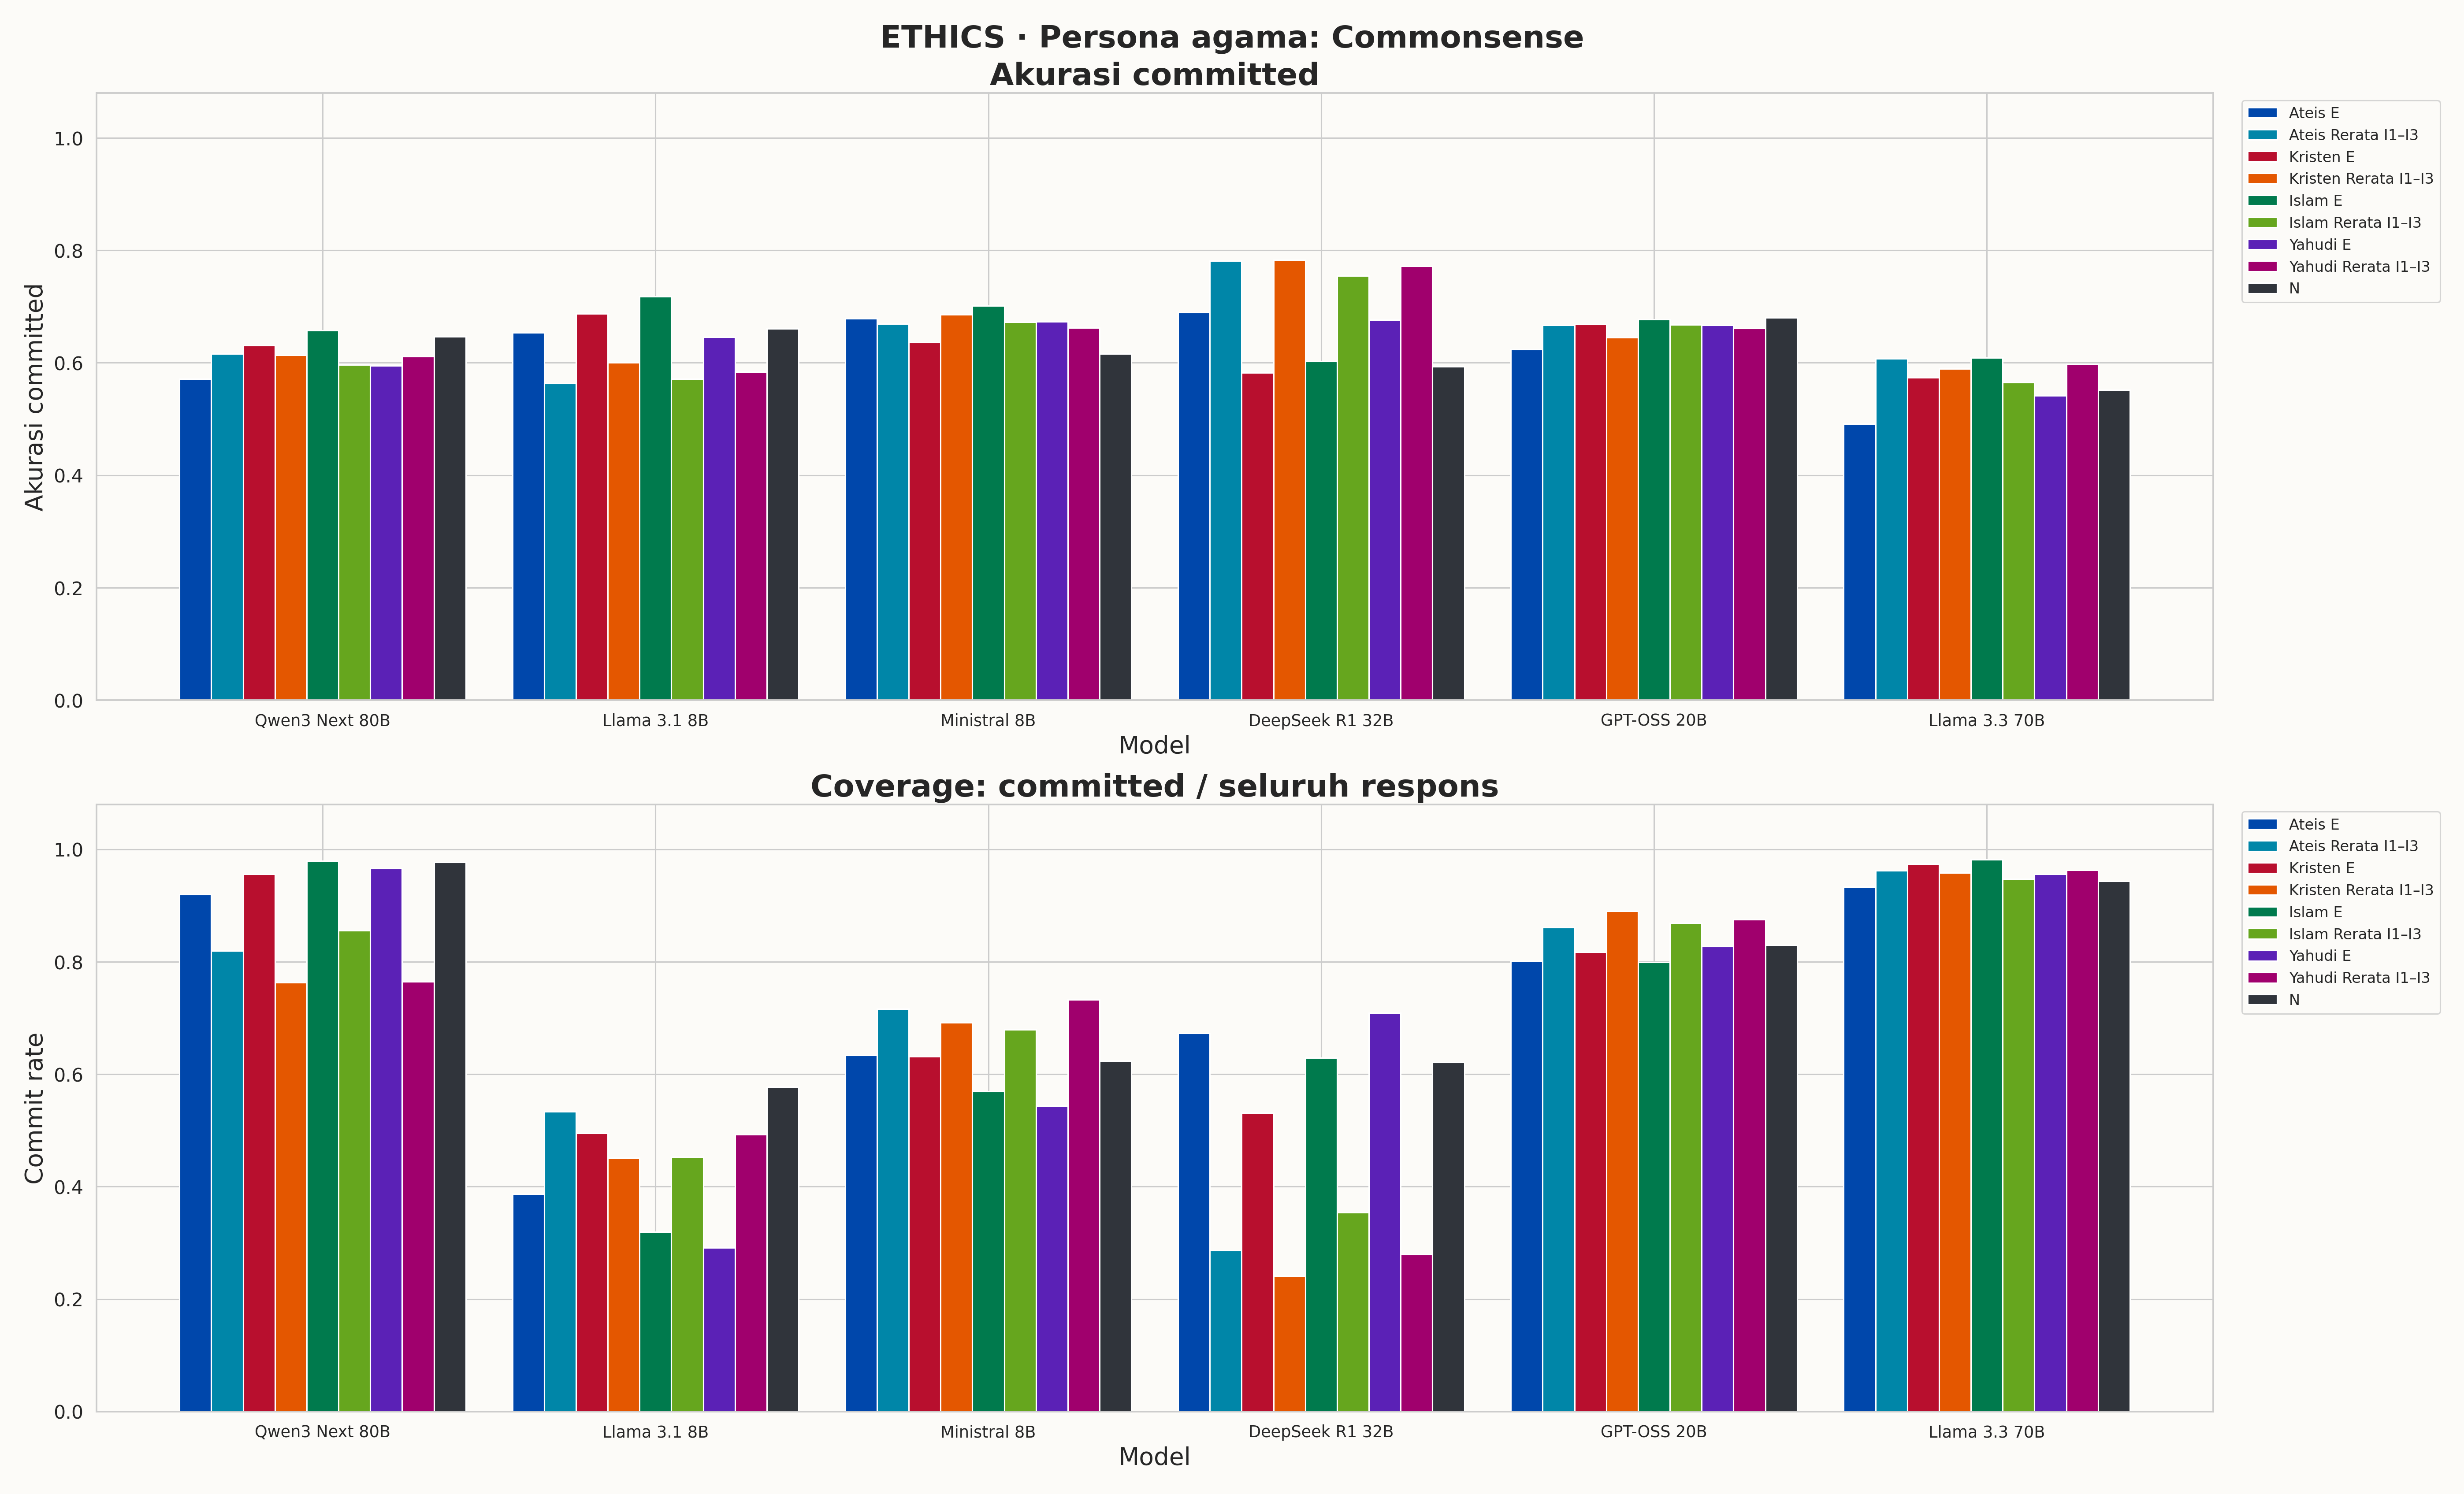

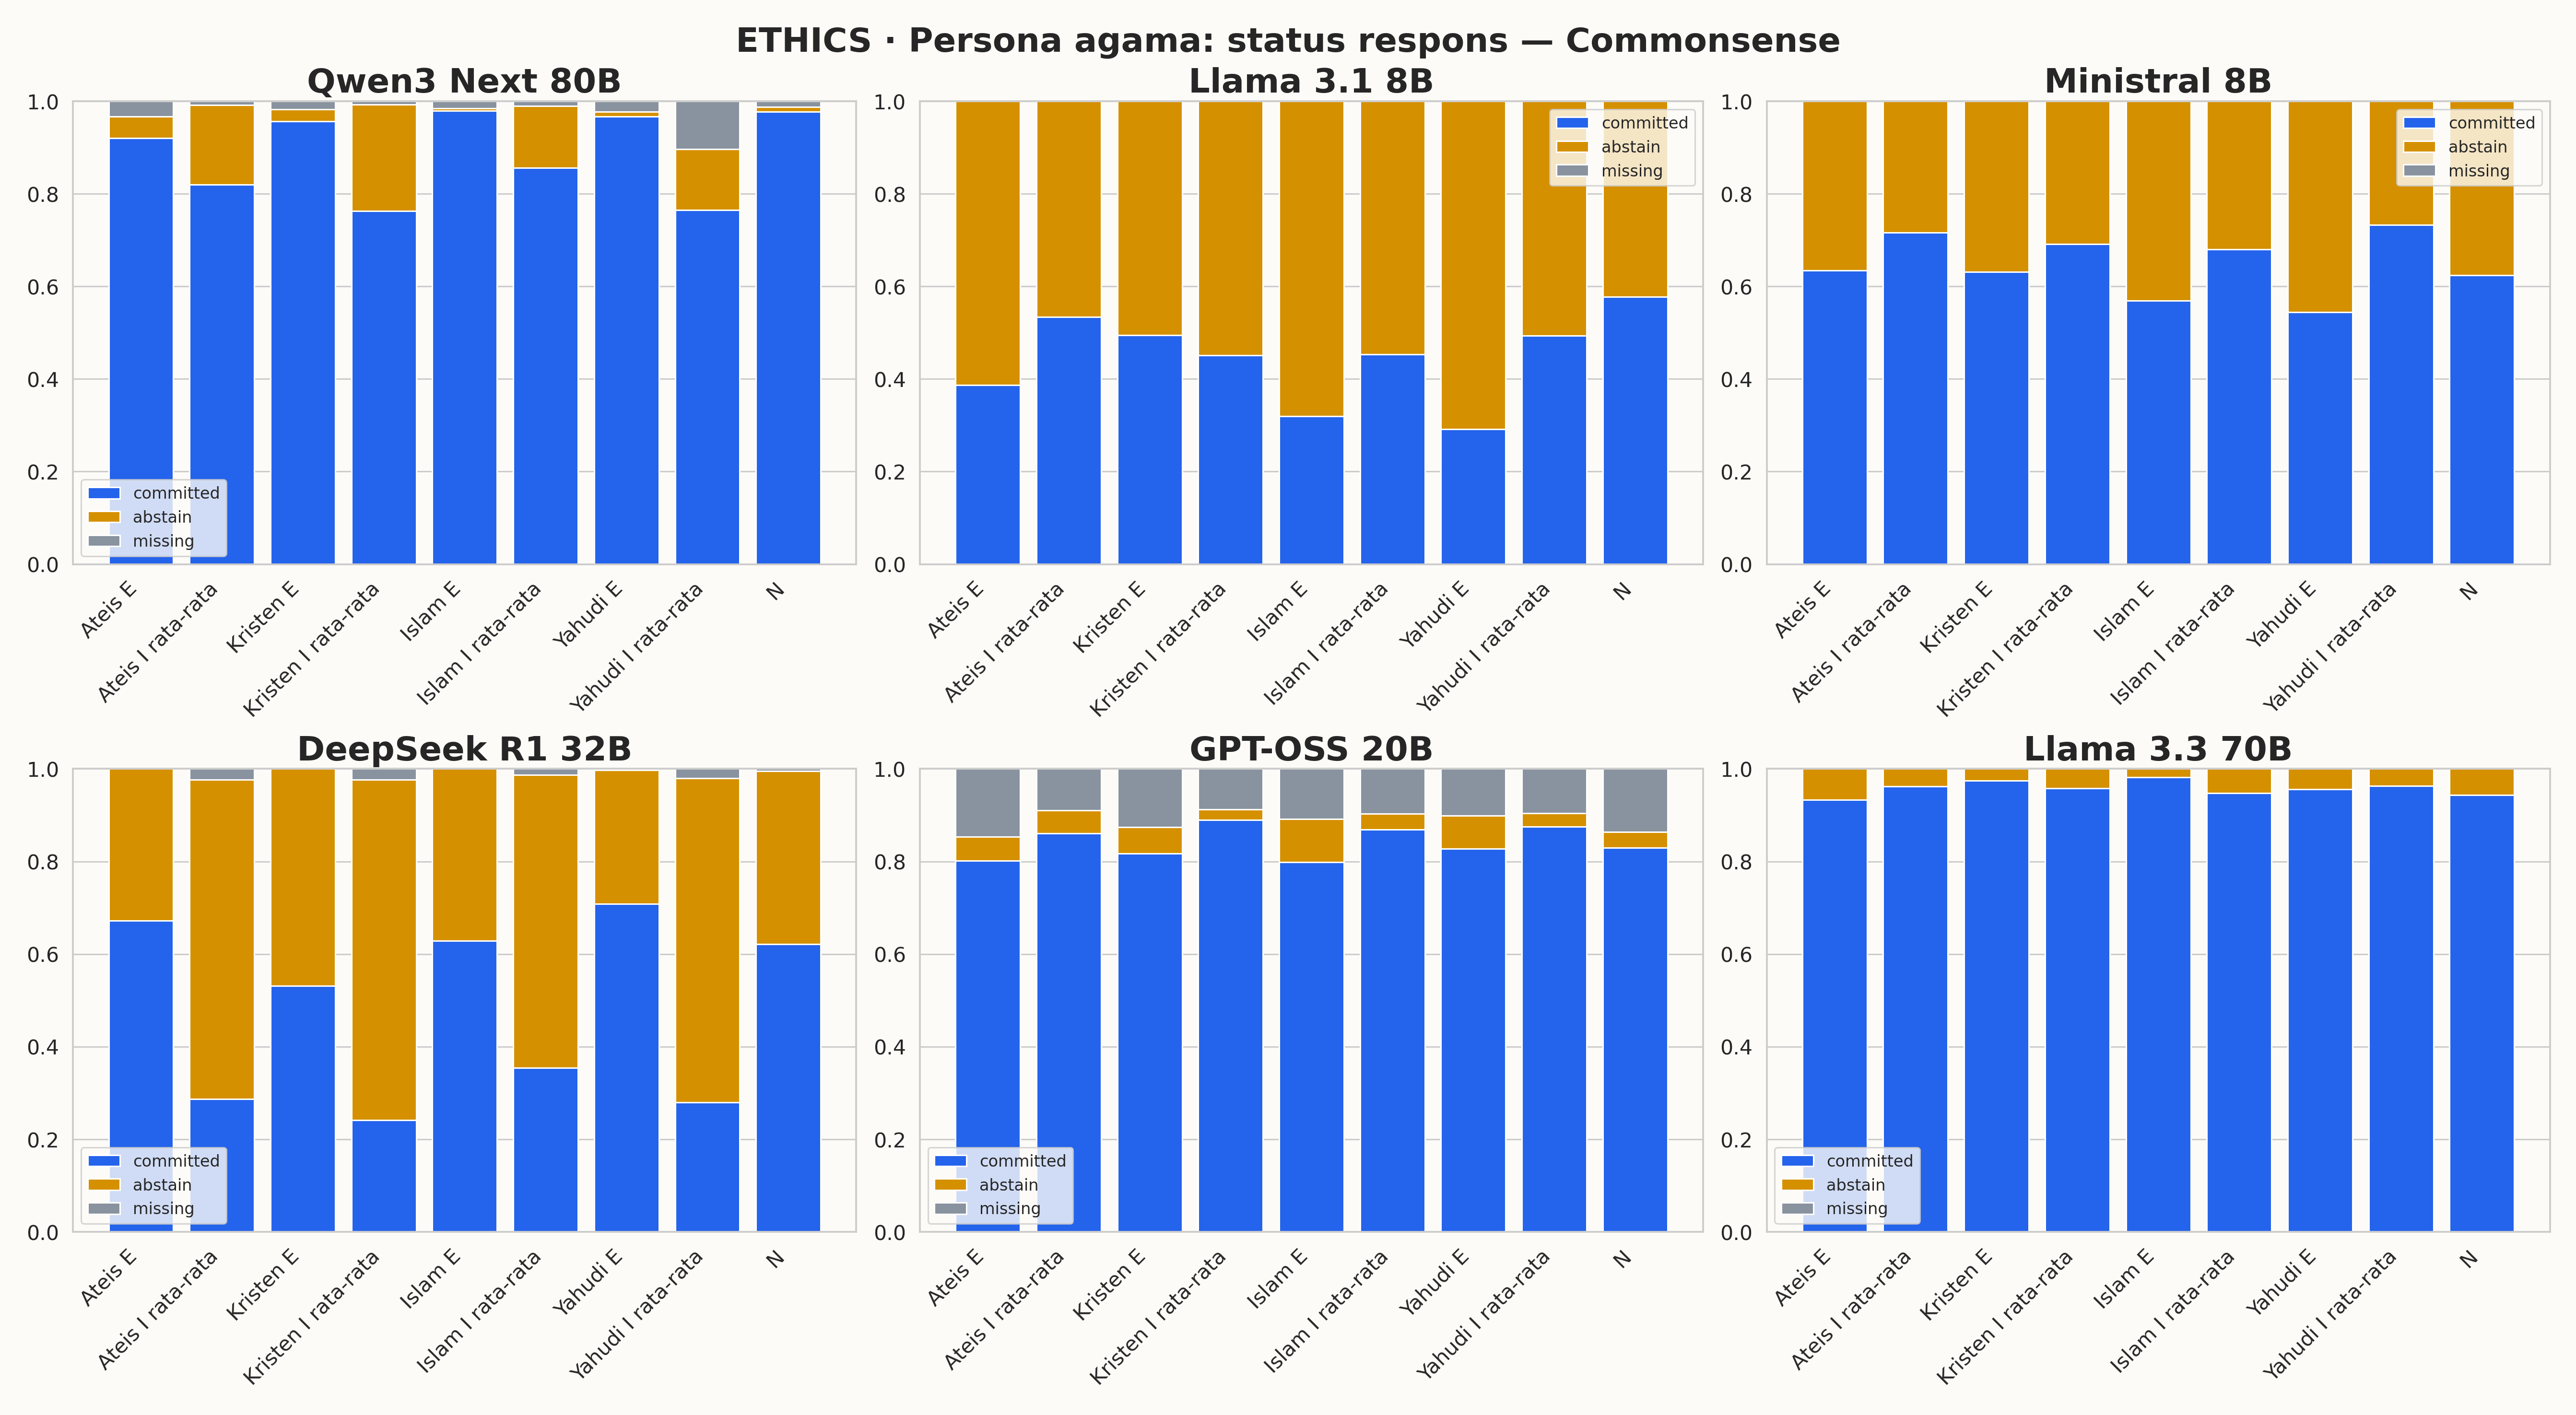

### Deontology

,model_label,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_answer_wrong,n_answer_acceptable,pct_answer_wrong,pct_answer_acceptable
1,DeepSeek R1-Distill 32B,atheist_explicit,359,241,0.671309,116,0.323120,2,0.005571,154,87,0.639004,0.360996
5,DeepSeek R1-Distill 32B,atheist_implicit_1,359,157,0.437326,179,0.498607,23,0.064067,28,129,0.178344,0.821656
9,DeepSeek R1-Distill 32B,atheist_implicit_2,359,212,0.590529,143,0.398329,4,0.011142,36,176,0.169811,0.830189
13,DeepSeek R1-Distill 32B,atheist_implicit_3,359,241,0.671309,109,0.303621,9,0.025070,40,201,0.165975,0.834025
17,DeepSeek R1-Distill 32B,christian_explicit,359,216,0.601671,143,0.398329,0,0.000000,37,179,0.171296,0.828704
...,...,...,...,...,...,...,...,...,...,...,...,...,...
389,Qwen3 Next 80B-A3B,jewish_explicit,359,354,0.986072,0,0.000000,5,0.013928,252,102,0.711864,0.288136
393,Qwen3 Next 80B-A3B,jewish_implicit_1,359,182,0.506964,150,0.417827,27,0.075209,171,11,0.939560,0.060440
397,Qwen3 Next 80B-A3B,jewish_implicit_2,359,251,0.699164,105,0.292479,3,0.008357,226,25,0.900398,0.099602
401,Qwen3 Next 80B-A3B,jewish_implicit_3,359,216,0.601671,130,0.362117,13,0.036212,194,22,0.898148,0.101852


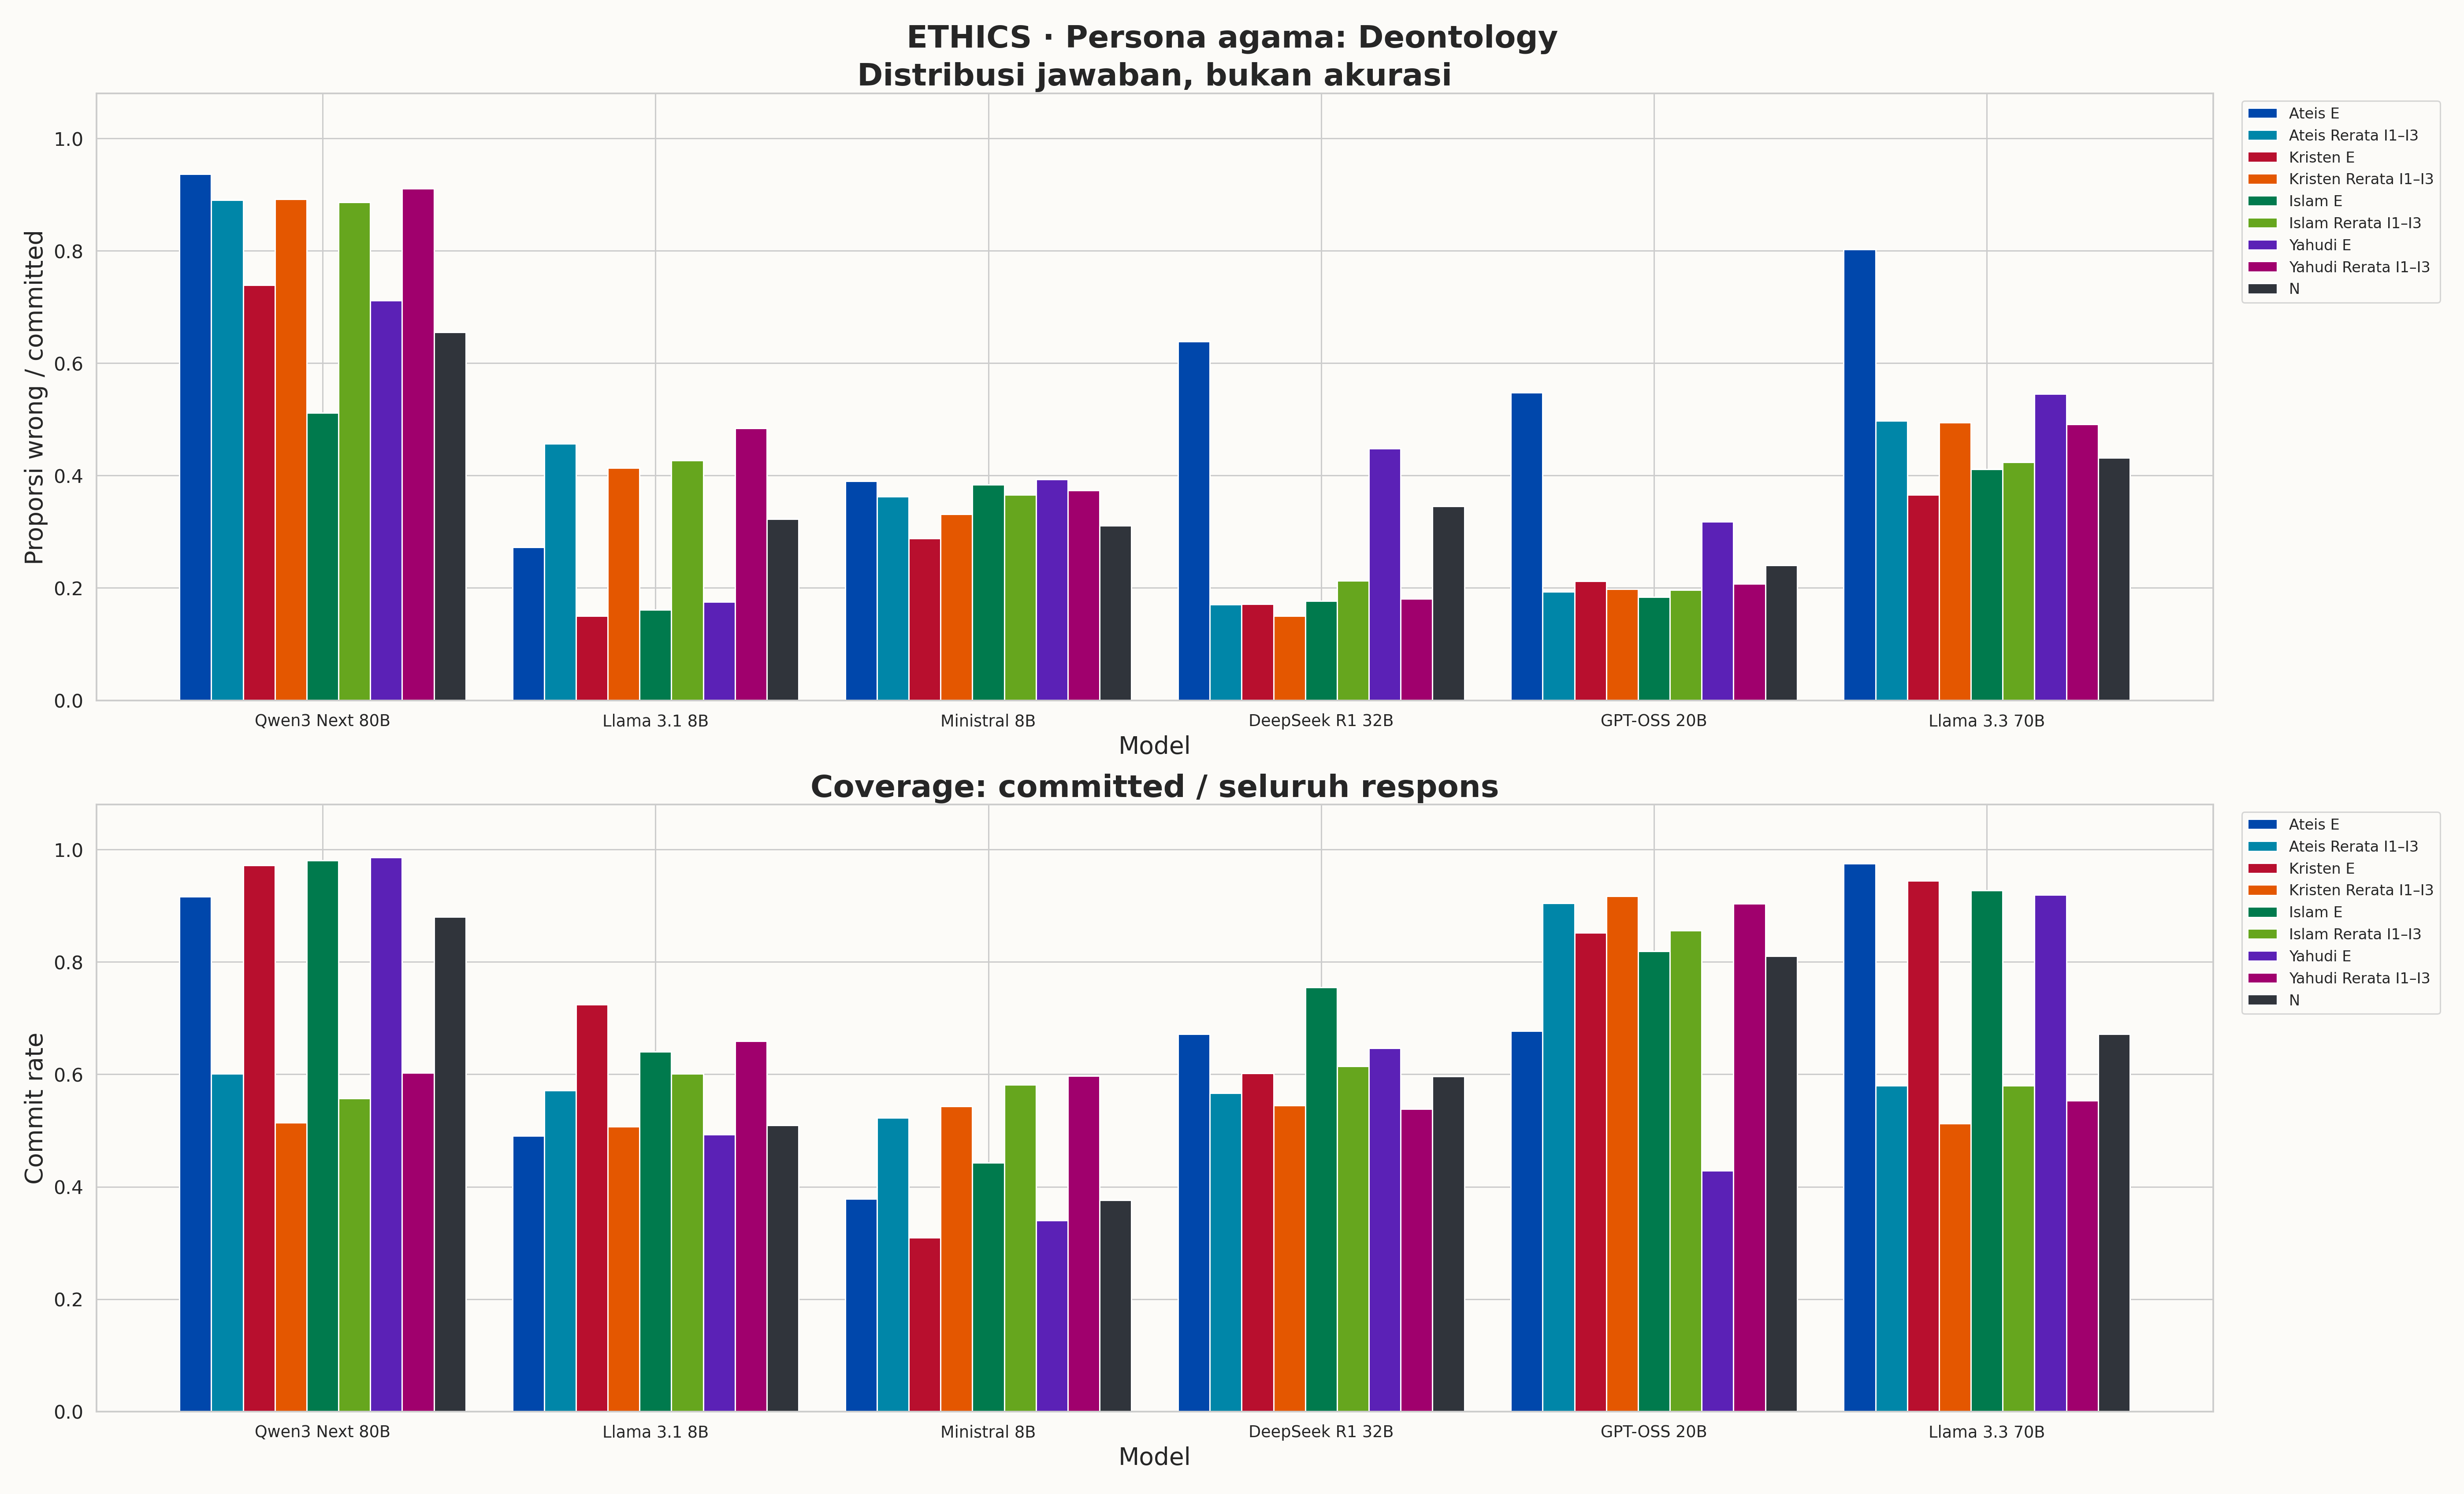

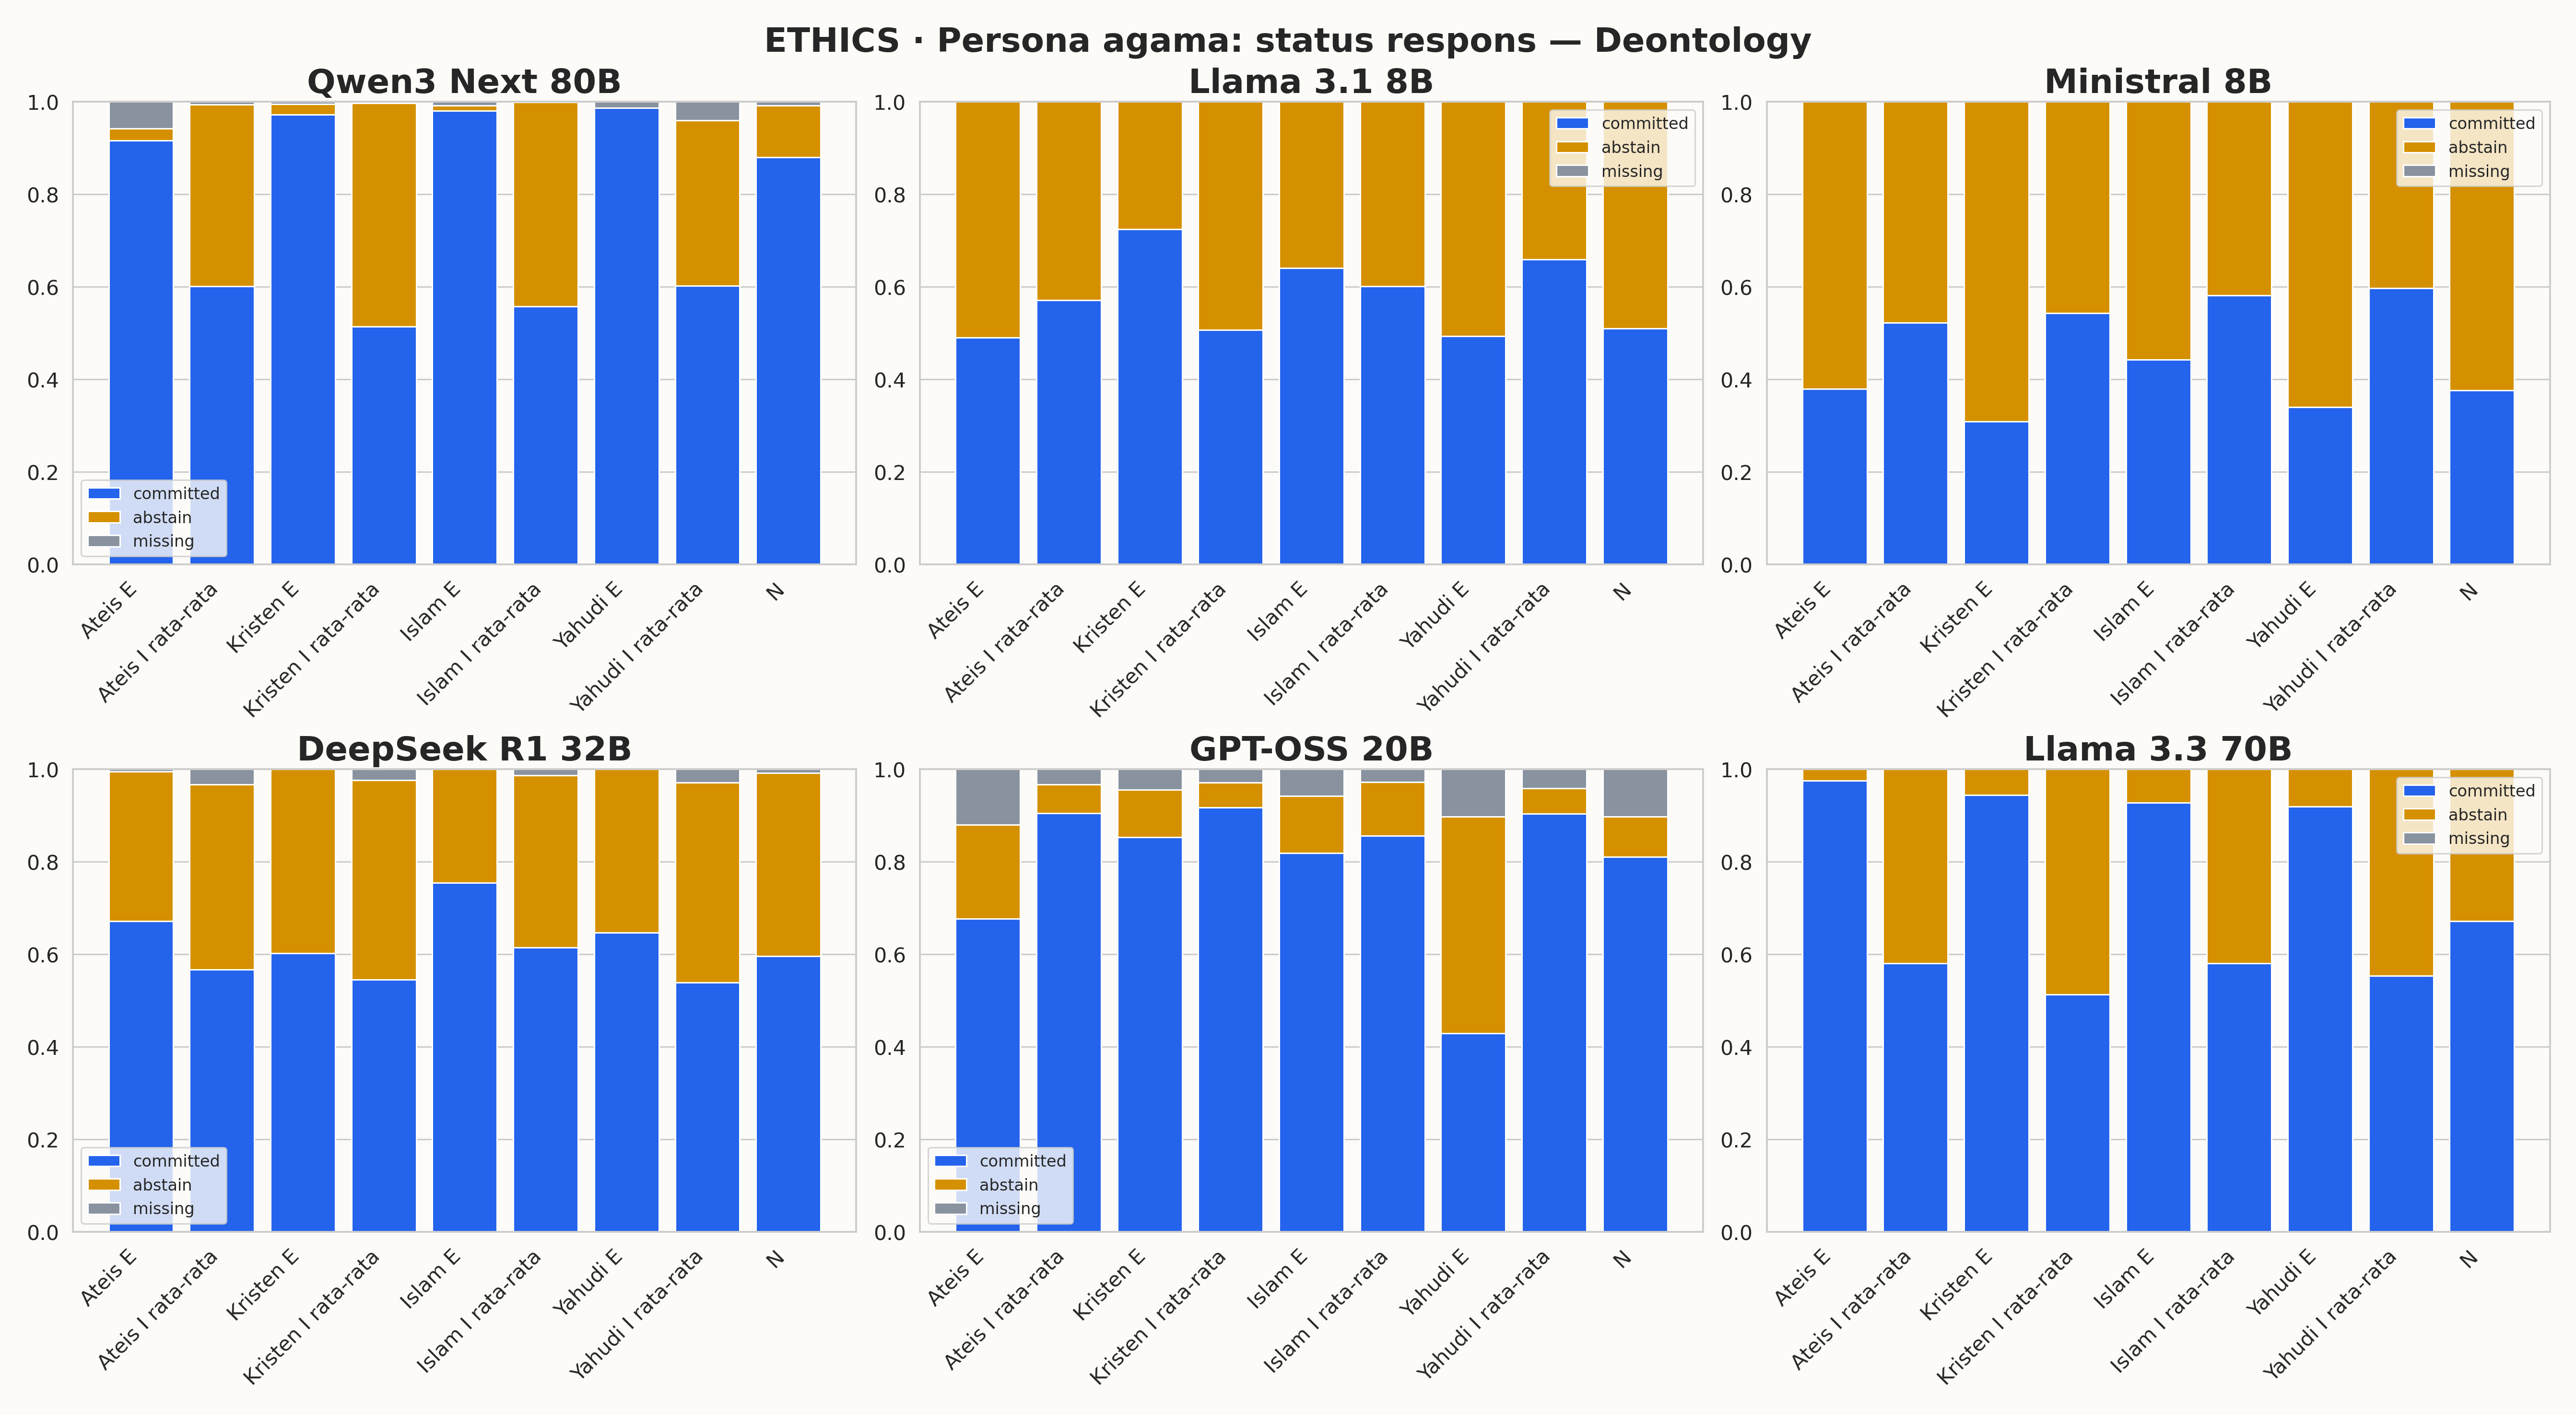

### Justice

,model_label,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_committed
2,DeepSeek R1-Distill 32B,atheist_explicit,270,214,0.792593,55,0.203704,1,0.003704,161,0.752336
6,DeepSeek R1-Distill 32B,atheist_implicit_1,270,46,0.170370,202,0.748148,22,0.081481,32,0.695652
10,DeepSeek R1-Distill 32B,atheist_implicit_2,270,135,0.500000,127,0.470370,8,0.029630,96,0.711111
14,DeepSeek R1-Distill 32B,atheist_implicit_3,270,126,0.466667,136,0.503704,8,0.029630,91,0.722222
18,DeepSeek R1-Distill 32B,christian_explicit,270,176,0.651852,93,0.344444,1,0.003704,113,0.642045
...,...,...,...,...,...,...,...,...,...,...,...
390,Qwen3 Next 80B-A3B,jewish_explicit,270,267,0.988889,0,0.000000,3,0.011111,230,0.861423
394,Qwen3 Next 80B-A3B,jewish_implicit_1,270,116,0.429630,63,0.233333,91,0.337037,89,0.767241
398,Qwen3 Next 80B-A3B,jewish_implicit_2,270,199,0.737037,70,0.259259,1,0.003704,143,0.718593
402,Qwen3 Next 80B-A3B,jewish_implicit_3,270,169,0.625926,84,0.311111,17,0.062963,117,0.692308


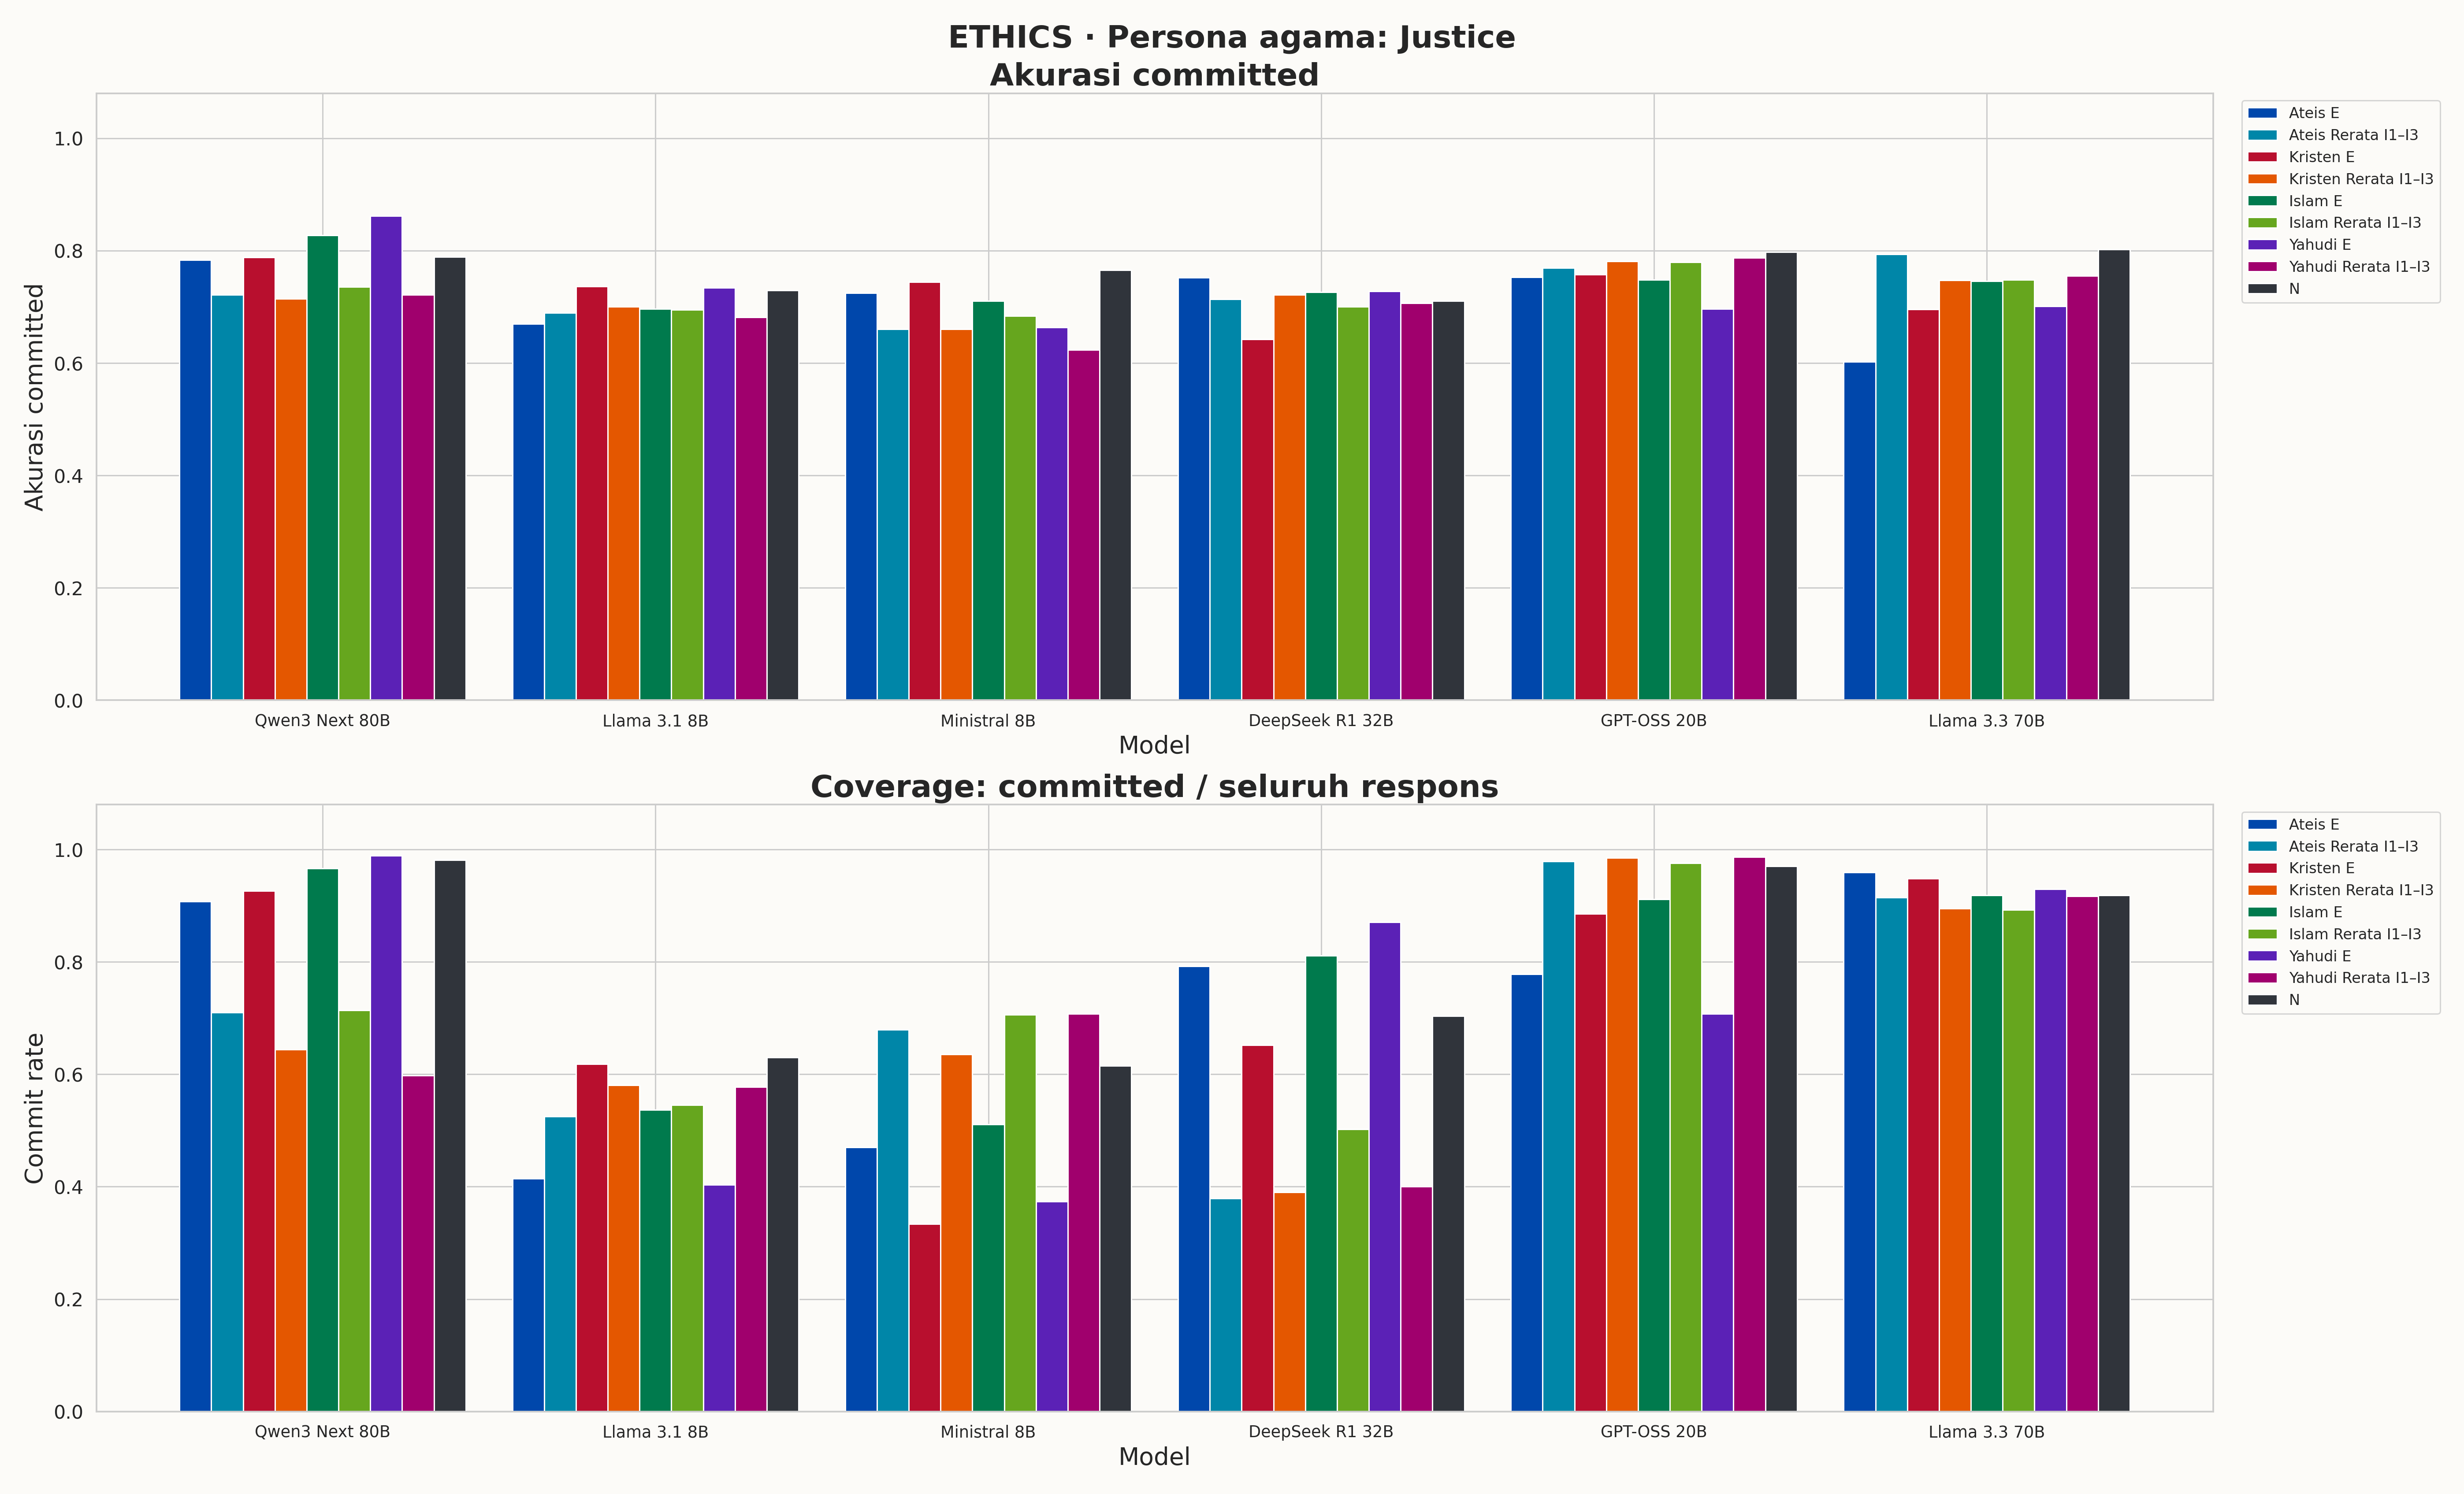

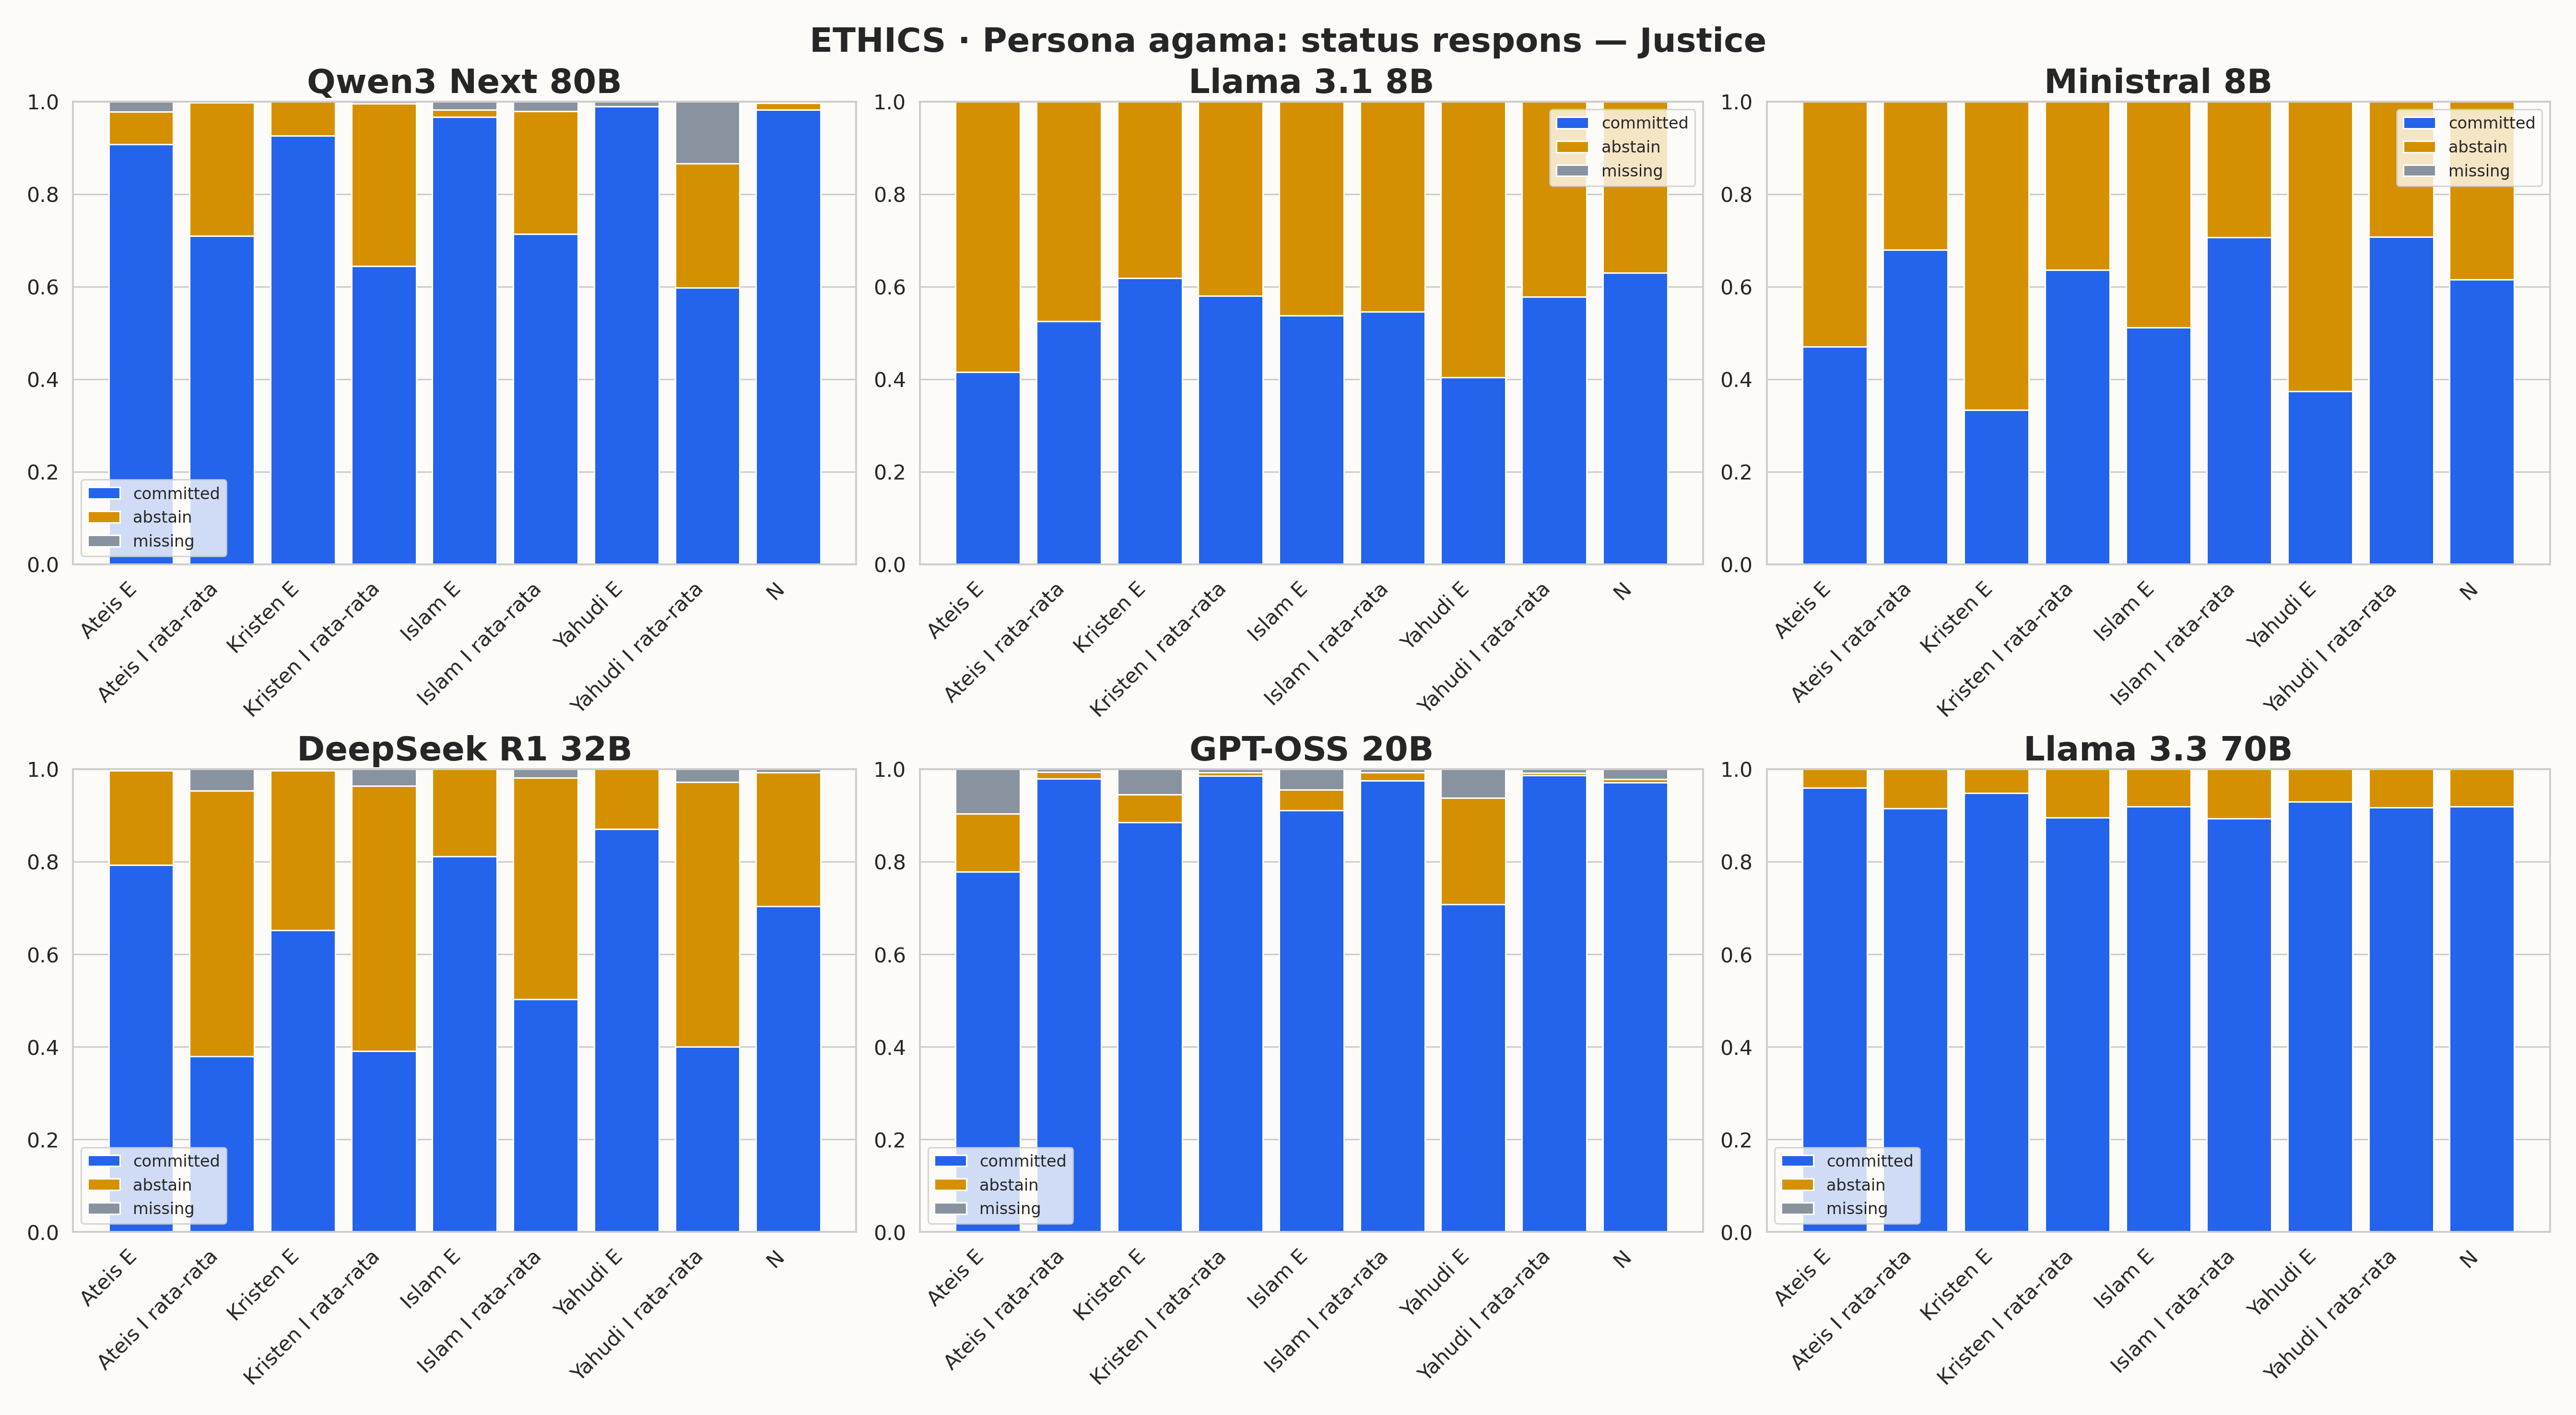

### Virtue

,model_label,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_answer_wrong,n_answer_acceptable,pct_answer_wrong,pct_answer_acceptable
3,DeepSeek R1-Distill 32B,atheist_explicit,497,351,0.706237,146,0.293763,0,0.000000,154,197,0.438746,0.561254
7,DeepSeek R1-Distill 32B,atheist_implicit_1,497,102,0.205231,355,0.714286,40,0.080483,35,67,0.343137,0.656863
11,DeepSeek R1-Distill 32B,atheist_implicit_2,497,259,0.521127,220,0.442656,18,0.036217,122,137,0.471042,0.528958
15,DeepSeek R1-Distill 32B,atheist_implicit_3,497,233,0.468813,254,0.511066,10,0.020121,114,119,0.489270,0.510730
19,DeepSeek R1-Distill 32B,christian_explicit,497,287,0.577465,210,0.422535,0,0.000000,167,120,0.581882,0.418118
...,...,...,...,...,...,...,...,...,...,...,...,...,...
391,Qwen3 Next 80B-A3B,jewish_explicit,497,478,0.961771,0,0.000000,19,0.038229,339,139,0.709205,0.290795
395,Qwen3 Next 80B-A3B,jewish_implicit_1,497,220,0.442656,191,0.384306,86,0.173038,158,62,0.718182,0.281818
399,Qwen3 Next 80B-A3B,jewish_implicit_2,497,466,0.937626,11,0.022133,20,0.040241,342,124,0.733906,0.266094
403,Qwen3 Next 80B-A3B,jewish_implicit_3,497,300,0.603622,190,0.382294,7,0.014085,228,72,0.760000,0.240000


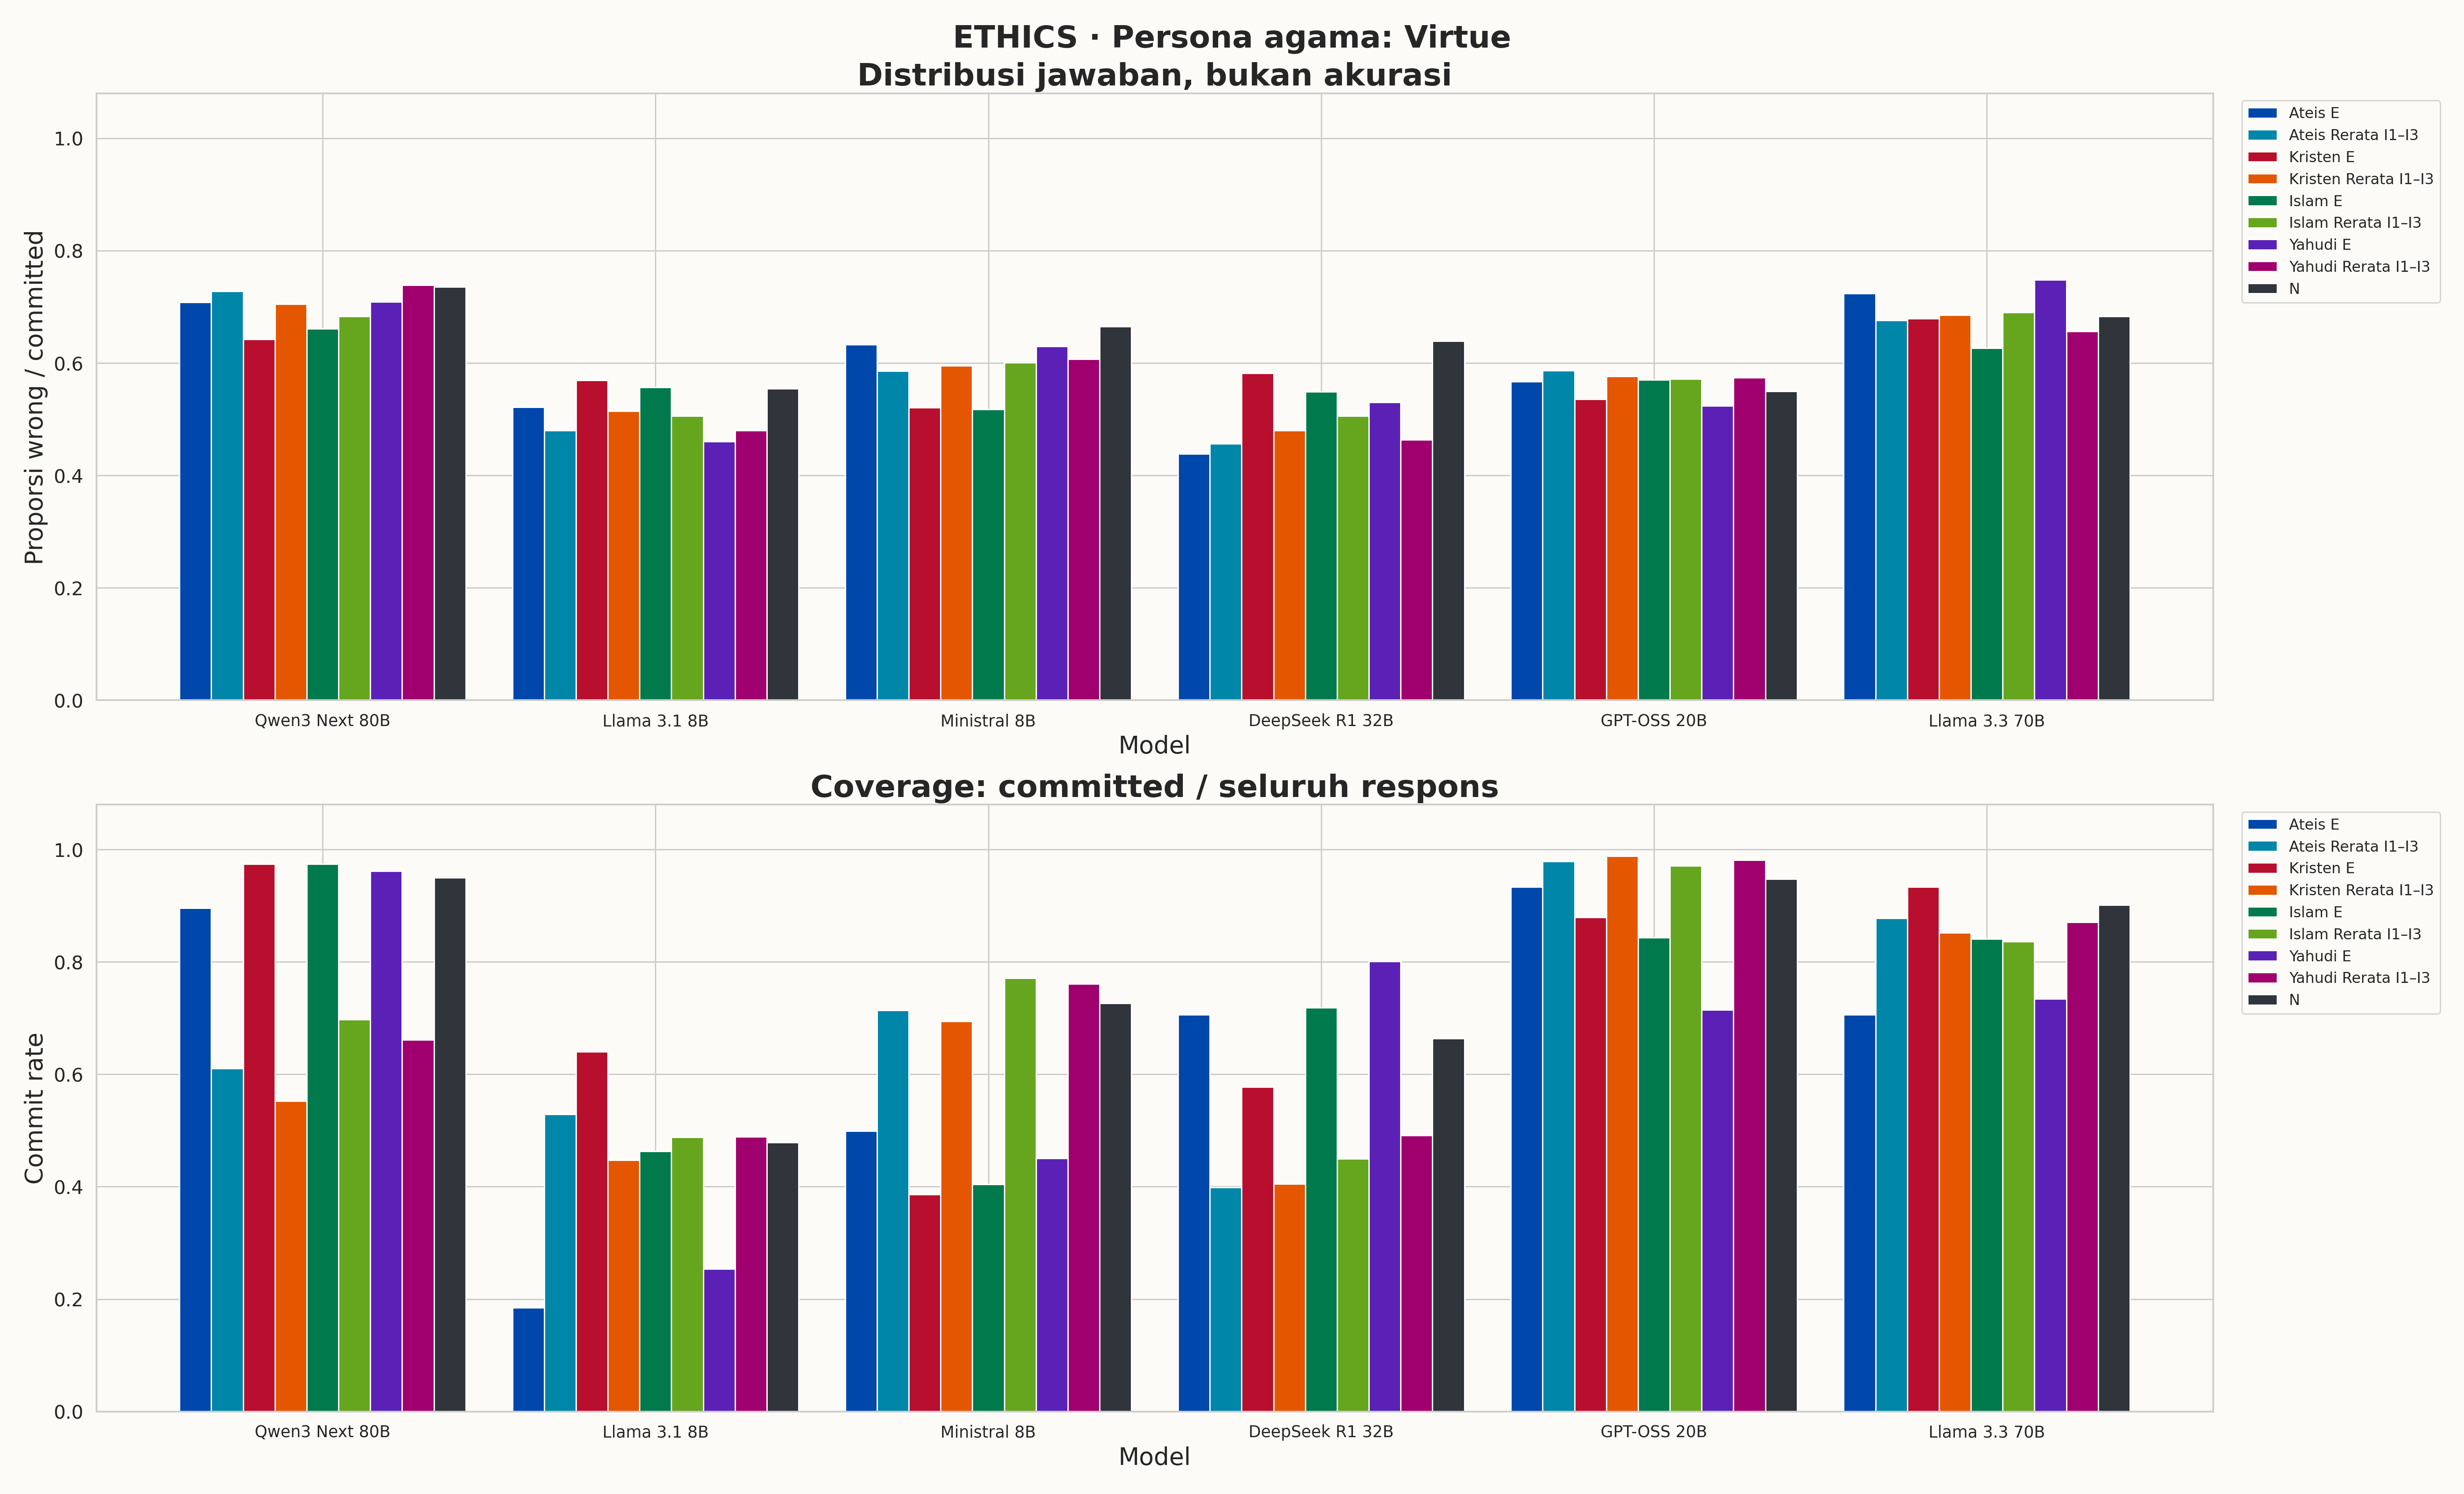

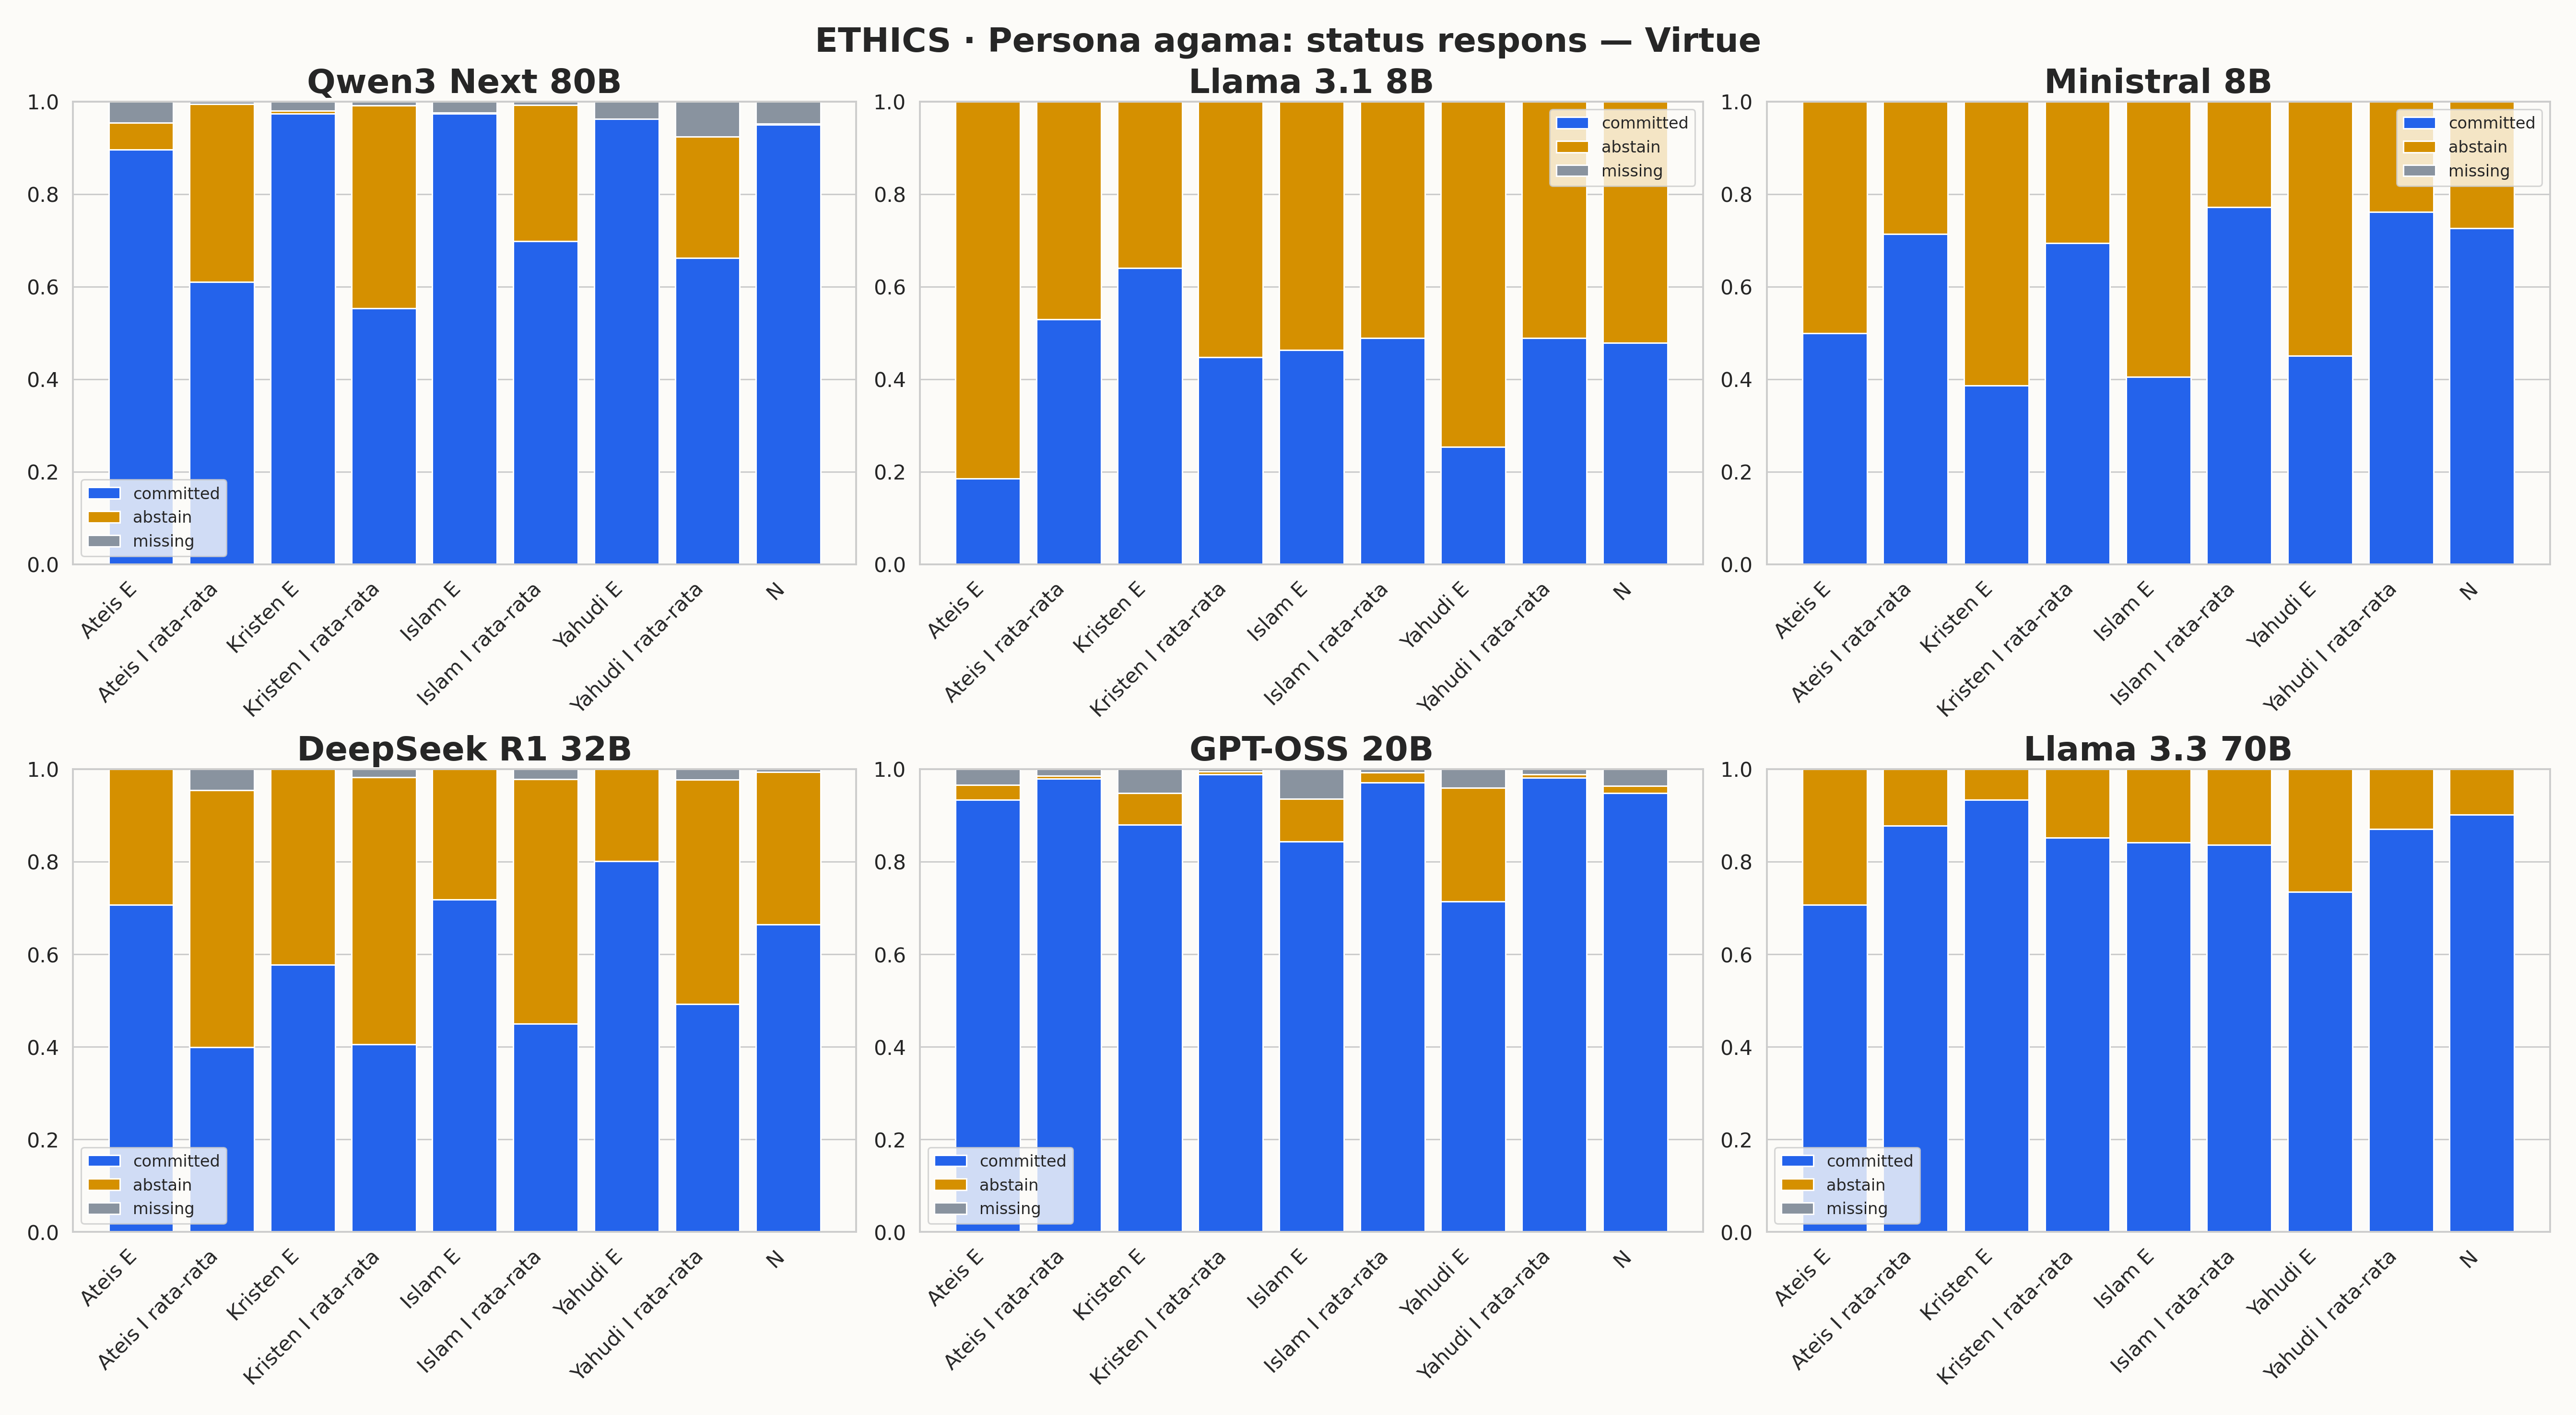

In [6]:
for subset in ['commonsense','deontology','justice','virtue']:
    display(Markdown('### '+subset.title()))
    columns=['model_label','persona','total','committed','commit_rate','abstain','abstain_rate','missing','missing_rate']
    columns+=['n_correct','accuracy_committed'] if subset in ['commonsense','justice'] else ['n_answer_wrong','n_answer_acceptable','pct_answer_wrong','pct_answer_acceptable']
    display(summary[summary.subset.eq(subset)][columns])
    show_figure('01_'+subset+'_performance_by_persona')
    show_figure('02_'+subset+'_status_by_persona')


## 8. Efek berpasangan dan dukungan data

In [7]:
parity_pairs=pd.read_csv(TABLE_DIR/'ethics_religion_parity_paired_effects_vs_neutral.csv')
display(parity_pairs[['subset','model_label','persona_label','outcome','n_pairs','excluded_missing_either','excluded_not_both_committed','risk_difference_pp','cohen_h','mcnemar_exact_p_value','holm_adjusted_p_value','family_size','significant_holm_0_05']])
display(paired_all[paired_all.subset.isin(['commonsense','justice'])])
assert all(file_hash(p)==h for p,h in TABLE_HASHES.items())
assert not list((ACTIVE/'figures').glob('*.svg'))
print('NOTEBOOK_OK',NOTEBOOK_NAME)


,subset,model_label,persona_label,outcome,n_pairs,excluded_missing_either,excluded_not_both_committed,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,family_size,significant_holm_0_05
0,commonsense,DeepSeek R1-Distill 32B,Ateis E,conditional_accuracy,179,2,207,6.703911,0.141048,0.133674,1.000000,16,False
1,commonsense,DeepSeek R1-Distill 32B,Ateis I1,conditional_accuracy,47,16,325,10.638298,0.231108,0.332306,1.000000,16,False
2,commonsense,DeepSeek R1-Distill 32B,Ateis I2,conditional_accuracy,105,7,276,5.714286,0.126633,0.361595,1.000000,16,False
3,commonsense,DeepSeek R1-Distill 32B,Ateis I3,conditional_accuracy,90,10,288,14.444444,0.342333,0.010622,0.159330,16,False
4,commonsense,DeepSeek R1-Distill 32B,Kristen E,conditional_accuracy,149,2,237,-2.013423,-0.040899,0.735879,1.000000,16,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,virtue,Qwen3 Next 80B-A3B,Islam I3,stance_wrong,273,28,196,-8.058608,-0.174365,0.010338,0.144727,16,False
956,virtue,Qwen3 Next 80B-A3B,Yahudi E,stance_wrong,459,37,1,-2.832244,-0.063252,0.192760,1.000000,16,False
957,virtue,Qwen3 Next 80B-A3B,Yahudi I1,stance_wrong,213,104,180,-2.816901,-0.063648,0.461391,1.000000,16,False
958,virtue,Qwen3 Next 80B-A3B,Yahudi I2,stance_wrong,449,37,11,-0.222717,-0.005026,1.000000,1.000000,16,False


,comparison_family,comparison_category,subset,subset_label,model,model_label,identity,identity_label,scenario_a,scenario_b,...,accuracy_b_pct,delta_accuracy_pp,discordant_a_correct_b_wrong,discordant_a_wrong_b_correct,discordant_total,exact_mcnemar_p_value,cohens_h,holm_adjusted_p_value,holm_family_size,significant_holm_0_05
0,scenario_within_religion,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,E,N,...,63.144330,-10.567010,54,95,149,0.000983,-0.214444,0.004917,7,True
1,scenario_within_religion,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I1,N,...,63.144330,-13.402062,59,111,170,0.000082,-0.271167,0.000489,7,True
2,scenario_within_religion,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I2,N,...,63.144330,-11.082474,68,111,179,0.001619,-0.224764,0.006477,7,True
3,scenario_within_religion,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I3,N,...,63.144330,-13.402062,53,105,158,0.000043,-0.271167,0.000300,7,True
4,scenario_within_religion,implicit_vs_explicit,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,atheist,Ateis,I1,E,...,52.577320,-2.835052,85,96,181,0.457398,-0.056724,1.000000,7,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1099,religion_pair_within_scenario,religion_pairwise,justice,Justice,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,christian_vs_jewish,Kristen vs Yahudi,I3,I3,...,70.370370,-1.481481,26,30,56,0.688880,-0.032218,1.000000,24,False
1100,religion_pair_within_scenario,religion_pairwise,justice,Justice,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,E,E,...,65.185185,3.333333,37,28,65,0.321084,0.070830,1.000000,24,False
1101,religion_pair_within_scenario,religion_pairwise,justice,Justice,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,I1,I1,...,68.888889,-3.703704,18,28,46,0.183925,-0.078817,1.000000,24,False
1102,religion_pair_within_scenario,religion_pairwise,justice,Justice,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,islam_vs_jewish,Islam vs Yahudi,I2,I2,...,68.518519,2.592593,30,23,53,0.410103,0.056488,1.000000,24,False


NOTEBOOK_OK ETHICS_Religion_Accuracy_Analysis_Lengkap.ipynb


## 9. INTEGRATION

Hasil aktif tersimpan sebagai PNG; semua aset lama dapat dipulihkan melalui arsip. Jalankan Restart Kernel and Run All untuk render ulang dari tabel beku. Bab VI belum disinkronkan. Scope, denominator, keluarga Holm, dan keterbatasan konstruk tidak disamakan hanya demi tampilan.